# Which Degrees Still Pay?
### A program-level decision-support tool for university program portfolio review

**MSIS 502B · Summer 2026 · Group 8**
Adonay Kfleyesus · Akshaya Jonnalagadda · Pragun Kalra · Santiago · Chelsea Chen

**Prepared for:** university academic leadership and the program review committee

---

We are building a decision-support tool for universities deciding which degree programs to
**open, expand, hold or restructure**. It is organised around *graduate outcomes* rather than
enrolment demand, and combines four dimensions — **earnings, student debt, occupational growth,
and AI exposure** — so programs can be compared side by side at the field x credential level.

### TL;DR — four findings

1. **Credential level is the single biggest lever — but what it is worth depends on the field.**
   +$12,341 per level in STEM, only +$8,146 in humanities and social sciences.
2. **Changing field matters far more than changing institution.**
   The top-to-bottom field spread is $68.4k; program + occupation inputs explain 66.9% of model importance versus 21.6% for the institution.
3. **AI exposure is a growth signal, not a risk signal.**
   In early-career pay bands above $70k, high-exposure groups show 29% median growth versus 10%
   for low-exposure groups; they are 3.2x less likely to be in the declining category. This is an association, not a causal estimate.
4. **Two-thirds of the catalogue has no reported earnings. We estimate all of it** — moving the
   university from a 33%-visible catalogue to a 100%-comparable one.

### How to read this notebook
Sections 1-2 frame the decision. Sections 3-6 build the analysis frame and document every
cleaning decision. Sections 7-9 explore the earnings, degree-level and AI patterns. Section 10 is the
model ladder, including an **ablation study that shows why the three-source join was necessary**.
Sections 12-15 deliver the estimates, insights, limitations and reflection.

---
# 1 · Business context

## 1.1 The decision on the table

Every budget cycle forces the same choice: which programs get more seats and faculty lines,
which hold steady, and which get restructured. Today that call rests on **enrolment demand** and
**how hard a department lobbies**. Neither says anything about how graduates actually do.

| Item | Detail |
|---|---|
| **Stakeholder** | The academic planning office and the program review committee |
| **Decision** | Which programs to open or expand, hold, or restructure |
| **Basis used today** | Enrolment demand + departmental advocacy |
| **What is missing** | How graduates actually do four years out |

## 1.2 Defining the pass mark — two yardsticks

A predicted earnings figure is not a decision. The university has to ask whether that number is
good enough. We set two thresholds; falling below **either** means the program does not pass.

**The floor — does it beat not going to college at all?**
The Department of Education publishes `pct_above_hs_threshold_5yr`: the share of graduates
out-earning a typical high-school graduate five years out.

**The pass mark — does it beat the national median for the same field and credential?**
That benchmark ships with the dataset (`national_median_earnings_4yr_usd`). We layer the
all-program median on top as a second yardstick.

## 1.3 The central obstacle

The earnings column is **74.5% empty** — not uncollected, but suppressed by the Department for
programs with small graduating cohorts, to protect privacy. The university can currently see
only a quarter of its own catalogue. Section 4 shows this missingness is **structural, not
random**, which is exactly why we model it rather than drop it.

---
# 2 · Setup

One colour system for the whole notebook, so eighteen charts read as one analysis rather than
eighteen. Categorical slots are assigned in fixed order and never cycled.

In [ ]:
import os, warnings, numpy as np, pandas as pd
import matplotlib.pyplot as plt, matplotlib.ticker as mtick, seaborn as sns
from matplotlib.colors import LinearSegmentedColormap

warnings.filterwarnings("ignore")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

CAT = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
       "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK, INK2, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#fcfcfb"
SEQ = LinearSegmentedColormap.from_list("seq", ["#cde2fb","#86b6ef","#3987e5","#256abf","#0d366b"])
DIV = LinearSegmentedColormap.from_list("div", ["#0d366b","#3987e5","#cde2fb","#f0efec","#f7c9a8","#e8823c","#8c3b06"])

sns.set_theme(style="whitegrid")
plt.rcParams.update({
    "figure.figsize": (10, 6), "figure.dpi": 110, "figure.facecolor": "white",
    "axes.facecolor": SURFACE, "axes.edgecolor": GRID, "axes.labelcolor": INK2,
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlecolor": INK,
    "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": INK2, "ytick.color": INK2, "font.size": 10,
    "legend.frameon": False, "axes.spines.top": False, "axes.spines.right": False,
})

USD = mtick.FuncFormatter(lambda v, _: f"${v/1000:,.0f}k" if abs(v) >= 1000 else f"${v:,.0f}")
PCT = mtick.FuncFormatter(lambda v, _: f"{v:.0f}%")

def finish(ax, title, subtitle="", xlab="", ylab="", legend_title=None):
    """One helper so every chart gets a title, a subtitle that states the finding, and labels."""
    ax.set_title(title, loc="left", pad=18 if subtitle else 10)
    if subtitle:
        ax.annotate(subtitle, xy=(0, 1.015), xycoords="axes fraction",
                    fontsize=9, color=INK2, va="bottom")
    ax.set_xlabel(xlab); ax.set_ylabel(ylab)
    if legend_title and ax.get_legend():
        ax.get_legend().set_title(legend_title)
    return ax

print("matplotlib", plt.matplotlib.__version__, "| seaborn", sns.__version__)

matplotlib 3.10.0 | seaborn 0.13.2


---
# 3 · Data understanding

## 3.1 Loading

One CSV, three federal sources stitched together. **One row = one institution x one field of
study x one credential level.** "University of Washington - Computer Science - Master's" is a
single row.

Getting the grain right matters: a 12-graduate certificate and a 900-graduate bachelor's
programme are both one row, so every field-level figure below is deliberately weighted by
credentials awarded rather than by row count.

In [ ]:
from pathlib import Path
import importlib.util
import subprocess
import sys

DATASET_HANDLE = "kylefengkfeng209/college-majors-2026-earnings-debt-jobs-ai"
DOWNLOAD_DIR = Path("/content/kaggle_data")
DATA_PATH = None

# Public Kaggle datasets usually download without credentials. If Kaggle access is
# unavailable, fall back to the CSV paths used by the original local workflow.
try:
    if importlib.util.find_spec("kagglehub") is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "kagglehub"])
    import kagglehub
    downloaded = Path(kagglehub.dataset_download(DATASET_HANDLE, output_dir=str(DOWNLOAD_DIR)))
    csvs = sorted(downloaded.rglob("*.csv"))
    preferred = [p for p in csvs if p.name == "college_majors_2026.csv"]
    DATA_PATH = preferred[0] if preferred else (csvs[0] if len(csvs) == 1 else None)
    if DATA_PATH is None:
        raise FileNotFoundError(f"Could not identify the dataset CSV in {downloaded}")
    print(f"Loaded dataset from Kaggle: {DATA_PATH}")
except Exception as kaggle_error:
    print(f"Kaggle download unavailable ({kaggle_error}); checking local files.")
    CANDIDATES = [
        "/content/college_majors_2026.csv",
        "/content/sample_data/college_majors_2026.csv",
        "college_majors_2026.csv",
        "/mnt/user-data/uploads/Downloads/college_majors_2026.csv",
    ]
    DATA_PATH = next((p for p in CANDIDATES if Path(p).exists()), None)
    if DATA_PATH is None:
        raise FileNotFoundError(
            "Kaggle download failed. Upload college_majors_2026.csv to Colab, "
            "then rerun this cell."
        ) from kaggle_error

print("reading:", DATA_PATH)
df_raw = pd.read_csv(DATA_PATH, low_memory=False)
print(f"Rows: {df_raw.shape[0]:,}   Columns: {df_raw.shape[1]}")
print(f"Memory: {df_raw.memory_usage(deep=True).sum()/1024**2:,.0f} MB")
df_raw.head(3)


Using Colab cache for faster access to the 'college-majors-2026-earnings-debt-jobs-ai' dataset.
Loaded dataset from Kaggle: /kaggle/input/college-majors-2026-earnings-debt-jobs-ai/college_majors_2026.csv
reading: /kaggle/input/college-majors-2026-earnings-debt-jobs-ai/college_majors_2026.csv
Rows: 227,980   Columns: 72
Memory: 362 MB


,program_id,unitid,opeid6,institution_name,institution_control,is_main_campus,institution_city,institution_state,institution_region,institution_latitude,...,occupations_using_ai_software,ai_software_occupation_share,expert_system_occupation_share,ai_tools_max_per_occupation,hot_technologies_mean_per_occupation,ai_tool_examples,earnings_4yr_status,earnings_1yr_status,earnings_5yr_status,debt_status
0,opeid031505-51.07-1,NaN,31505,A - Technical College,"Private, for-profit",1,NaN,NaN,NaN,NaN,...,1.0,0.053,0.368,1.0,31.95,OpenAI ChatGPT,reported,reported,reported,reported
1,opeid031505-51.35-1,NaN,31505,A - Technical College,"Private, for-profit",1,NaN,NaN,NaN,NaN,...,0.0,0.000,0.000,0.0,5.50,NaN,privacy_suppressed,privacy_suppressed,privacy_suppressed,privacy_suppressed
2,opeid031505-52.04-1,NaN,31505,A - Technical College,"Private, for-profit",1,NaN,NaN,NaN,NaN,...,0.0,0.000,0.167,0.0,18.11,NaN,reported,privacy_suppressed,privacy_suppressed,privacy_suppressed


## 3.2 What is in the file — four source blocks

The 72 columns come from three stitched sources. Grouping them this way is more useful than
listing them alphabetically, because each block has different missingness behaviour and a
different role in the analysis.

| Source | What it contributes |
|---|---|
| **College Scorecard** (U.S. Dept. of Education) | Graduate earnings at 1, 4 and 5 years; federal debt; monthly payment; employment |
| **BLS Occupational Projections** | Median wage, 2024-34 growth, and annual openings for the destination occupation |
| **O\*NET** | Which software tools each occupation actually uses, including AI tools |

**Official references:** [College Scorecard](https://collegescorecard.ed.gov/data/),
[BLS Occupational Employment and Wage Statistics](https://www.bls.gov/oes/),
[BLS Employment Projections](https://www.bls.gov/emp/), and
[O*NET OnLine](https://www.onetonline.org/).


In [ ]:
BLOCKS = {
    "Identity":    ["program_id", "unitid", "opeid6", "institution_name"],
    "Institution": [c for c in df_raw.columns if c.startswith("institution_")
                    and c != "institution_name"] + ["is_main_campus"],
    "Program":     ["cip_code_4digit", "cip_title", "cip_family_code", "cip_family_title",
                    "credential_level", "credential_name", "distance_education",
                    "awards_year1", "awards_year2", "outcomes_shared_across_campuses"],
    "Earnings":    [c for c in df_raw.columns if "earnings" in c or "working" in c
                    or "hs_threshold" in c],
    "Debt":        [c for c in df_raw.columns if "debt" in c or "payment" in c],
    "Occupation":  [c for c in df_raw.columns if c.startswith("occupation_")
                    or "linked_occupation" in c],
    "AI exposure": [c for c in df_raw.columns if c.startswith(("ai_", "expert_system", "hot_"))
                    or c == "occupations_using_ai_software"],
}

schema = pd.DataFrame({
    "dtype":     df_raw.dtypes.astype(str),
    "missing_%": (df_raw.isna().mean() * 100).round(1),
    "n_unique":  df_raw.nunique(),
})
seen, rows = set(), []
for block, cols in BLOCKS.items():
    for c in cols:
        if c in df_raw.columns and c not in seen:
            seen.add(c); rows.append((block, c) + tuple(schema.loc[c]))
for c in df_raw.columns:
    if c not in seen:
        rows.append(("Status flags", c) + tuple(schema.loc[c]))

schema_tbl = pd.DataFrame(rows, columns=["block", "column", "dtype", "missing_%", "n_unique"])
print(schema_tbl.groupby("block", sort=False).agg(
    columns=("column", "size"), mean_missing_pct=("missing_%", "mean")).round(1).to_string())
schema_tbl.head(12)

             columns  mean_missing_pct
block                                 
Identity           4               0.8
Institution       13              11.8
Program           10               2.6
Earnings          23              60.9
Debt               5              62.9
Occupation        11               1.7
AI exposure        6              14.0


,block,column,dtype,missing_%,n_unique
0,Identity,program_id,object,0.0,227980
1,Identity,unitid,float64,3.1,6127
2,Identity,opeid6,int64,0.0,6033
3,Identity,institution_name,object,0.0,6774
4,Institution,institution_control,object,0.0,4
5,Institution,institution_city,object,5.0,2222
6,Institution,institution_state,object,5.0,59
7,Institution,institution_region,object,5.0,10
8,Institution,institution_latitude,float64,5.0,5623
9,Institution,institution_longitude,float64,5.0,5623


## 3.3 Where the blanks are — and why

Two charts. The left one shows *which* columns are empty. The right one shows *why*: reporting
rate rises monotonically with program size, from about 5% in the smallest decile to 80% in the
largest. **The missingness is a finding about the privacy rule, not a defect in the file.**

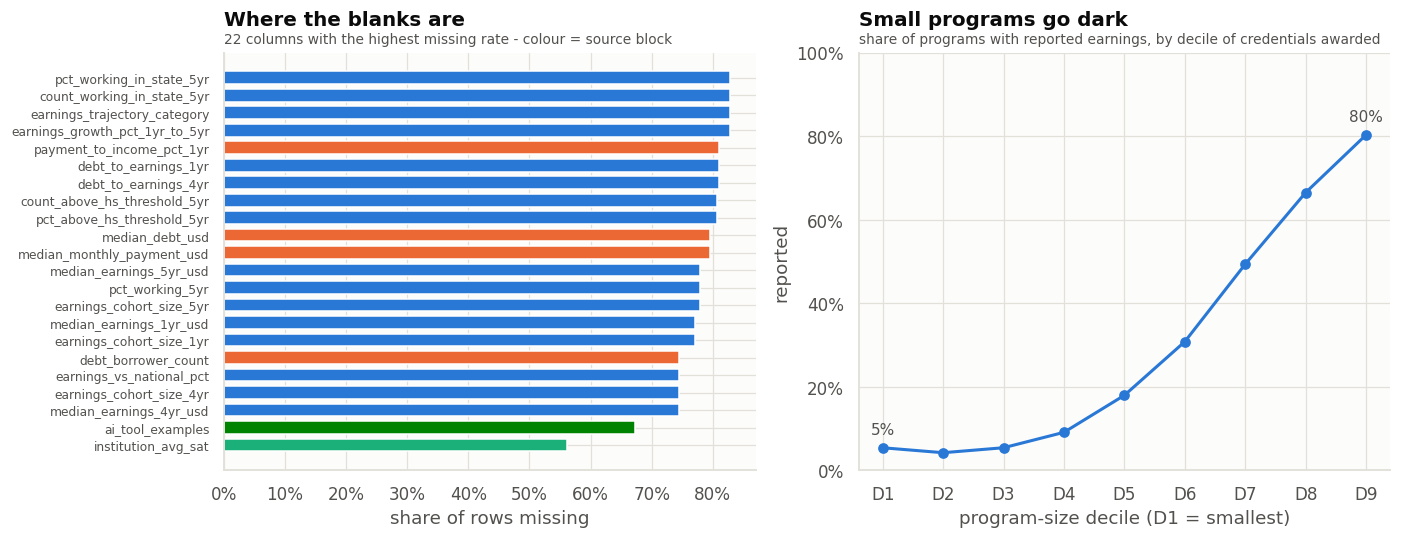

Reported earnings : 58,112 (25.5%)
Privacy-suppressed: 169,868


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

miss = (df_raw.isna().mean() * 100).sort_values(ascending=False).head(22)[::-1]
block_of = dict(zip(schema_tbl["column"], schema_tbl["block"]))
order = ["Earnings", "Debt", "Institution", "Program", "Occupation", "AI exposure",
         "Identity", "Status flags"]
colors = [CAT[order.index(block_of.get(c, "Status flags")) % len(CAT)] for c in miss.index]
axes[0].barh(miss.index, miss.values, color=colors, height=0.72)
axes[0].xaxis.set_major_formatter(PCT)
axes[0].tick_params(axis="y", labelsize=8)
finish(axes[0], "Where the blanks are",
       "22 columns with the highest missing rate - colour = source block",
       "share of rows missing", "")

size_bins = pd.qcut(df_raw["awards_year2"], 10, duplicates="drop", labels=False)
rate = (df_raw.assign(_d=size_bins, _rep=df_raw["earnings_4yr_status"].eq("reported"))
              .groupby("_d")["_rep"].mean() * 100)
axes[1].plot(rate.index, rate.values, marker="o", color=CAT[0], lw=2)
axes[1].set_xticks(range(len(rate)))
axes[1].set_xticklabels([f"D{i+1}" for i in range(len(rate))])
axes[1].yaxis.set_major_formatter(PCT); axes[1].set_ylim(0, 100)
for i, v in [(0, rate.iloc[0]), (len(rate)-1, rate.iloc[-1])]:
    axes[1].annotate(f"{v:.0f}%", (i, v), xytext=(0, 9), textcoords="offset points",
                     ha="center", color=INK2, fontsize=10)
finish(axes[1], "Small programs go dark",
       "share of programs with reported earnings, by decile of credentials awarded",
       "program-size decile (D1 = smallest)", "reported")
plt.tight_layout(); plt.show()

print(f"Reported earnings : {df_raw['earnings_4yr_status'].eq('reported').sum():,} "
      f"({df_raw['earnings_4yr_status'].eq('reported').mean()*100:.1f}%)")
print(f"Privacy-suppressed: {df_raw['earnings_4yr_status'].eq('privacy_suppressed').sum():,}")

**Read this chart.** Every earnings- and debt-derived column sits in the 70-85% missing range,
and they are all suppressed together for the same programs. The right panel is the mechanism:
only ~5% of the smallest decile reports, against 80% of the largest. Suppression is driven by
cohort size, which means dropping those rows would bias every conclusion toward large programs.

**So what.** This one fact determines the whole architecture of the analysis: the columns that
survive suppression become our inputs, and the columns that do not become our target.

---
# 4 · Data cleaning — a six-step funnel

Every step below has a business reason, not just a data reason. We report what each one removes
so the reader can disagree with any single decision without discarding the rest.

In [ ]:
funnel = []
def step(name, frame, note=""):
    funnel.append({"step": name, "rows": len(frame), "note": note})
    return frame

d = step("0 · Raw file as downloaded", df_raw)

before = len(d); d = d.drop_duplicates(subset="program_id")
d = step("1 · Drop duplicate program_id", d, f"removed {before-len(d):,}")

before = len(d); d = d[d["institution_control"].ne("Foreign")]
d = step("2 · US institutions only", d, f"removed {before-len(d):,}")

KEEP_CRED = ["Undergraduate Certificate or Diploma", "Associate's Degree", "Bachelor's Degree",
             "Master's Degree", "Doctoral Degree", "First Professional Degree"]
before = len(d); d = d[d["credential_name"].isin(KEEP_CRED)]
d = step("3 · Keep 6 standard credential levels", d, f"removed {before-len(d):,}")

before = len(d); d = d[d["largest_linked_occupation_soc"].notna()]
d = step("4 · Must map to a BLS/O*NET occupation", d, f"removed {before-len(d):,}")

before = len(d); d = d[d["awards_year2"].notna() & (d["awards_year2"] > 0)]
d = step("5 · Must award credentials (> 0)", d, f"removed {before-len(d):,}")

before = len(d)
d = d[(d["median_earnings_4yr_usd"].isna()) | (d["median_earnings_4yr_usd"] > 0)]
d = d[(d["median_debt_usd"].isna())          | (d["median_debt_usd"] > 0)]
d = step("6 · Drop impossible values", d, f"removed {before-len(d):,}")

fun = pd.DataFrame(funnel)
fun["kept_%"] = (fun["rows"] / fun.loc[0, "rows"] * 100).round(1)
print(fun.to_string(index=False))
print(f"\nKEPT {len(d):,} of {len(df_raw):,}  ({len(d)/len(df_raw)*100:.1f}%)")

# Normalize detailed source labels into the six standard degree levels used in
# every comparison. Keep credential_name unchanged for source traceability.
DEGREE_LEVEL_MAP = {
    "Undergraduate Certificate or Diploma": "Certificate",
    "Associate's Degree": "Associate",
    "Bachelor's Degree": "Bachelor's (Baccalaureate)",
    "Master's Degree": "Master's",
    "First Professional Degree": "First Professional",
    "Doctoral Degree": "Doctoral",
}
DEGREE_LEVEL_ORDER = [
    "Certificate", "Associate", "Bachelor's (Baccalaureate)",
    "Master's", "First Professional", "Doctoral",
]
d["degree_level_6"] = d["credential_name"].map(DEGREE_LEVEL_MAP)
if d["degree_level_6"].isna().any():
    unknown = sorted(d.loc[d["degree_level_6"].isna(), "credential_name"].dropna().unique())
    raise ValueError(f"Unexpected credential labels after filtering: {unknown}")
d["degree_level_6"] = pd.Categorical(
    d["degree_level_6"], categories=DEGREE_LEVEL_ORDER, ordered=True
)
print("Six standard degree levels:", ", ".join(DEGREE_LEVEL_ORDER))


                                  step   rows           note  kept_%
            0 · Raw file as downloaded 227980                  100.0
         1 · Drop duplicate program_id 227980      removed 0   100.0
              2 · US institutions only 223318  removed 4,662    98.0
 3 · Keep 6 standard credential levels 206536 removed 16,782    90.6
4 · Must map to a BLS/O*NET occupation 201771  removed 4,765    88.5
      5 · Must award credentials (> 0) 150565 removed 51,206    66.0
            6 · Drop impossible values 150565      removed 0    66.0

KEPT 150,565 of 227,980  (66.0%)
Six standard degree levels: Certificate, Associate, Bachelor's (Baccalaureate), Master's, First Professional, Doctoral


Why each cut, in one line:

| Step | Why |
|---|---|
| **1 · duplicates** | Zero found — but we run it to *prove* the file is clean rather than assume it |
| **2 · foreign institutions** | Median earnings $83,833 would skew every benchmark, and they are not a U.S. university's decision |
| **3 · credential levels** | "Non-credential programs" and post-baccalaureate certificates are not "should we open a program" decisions |
| **4 · occupation mapping** | Without it there is no BLS demand signal and no O\*NET AI signal — the row cannot be scored |
| **5 · credentials awarded > 0** | The biggest cut. These are **dormant or discontinued programs**; asking whether to expand them is meaningless |
| **6 · impossible values** | Negative earnings, zero debt. None in practice, but the check is cheap |

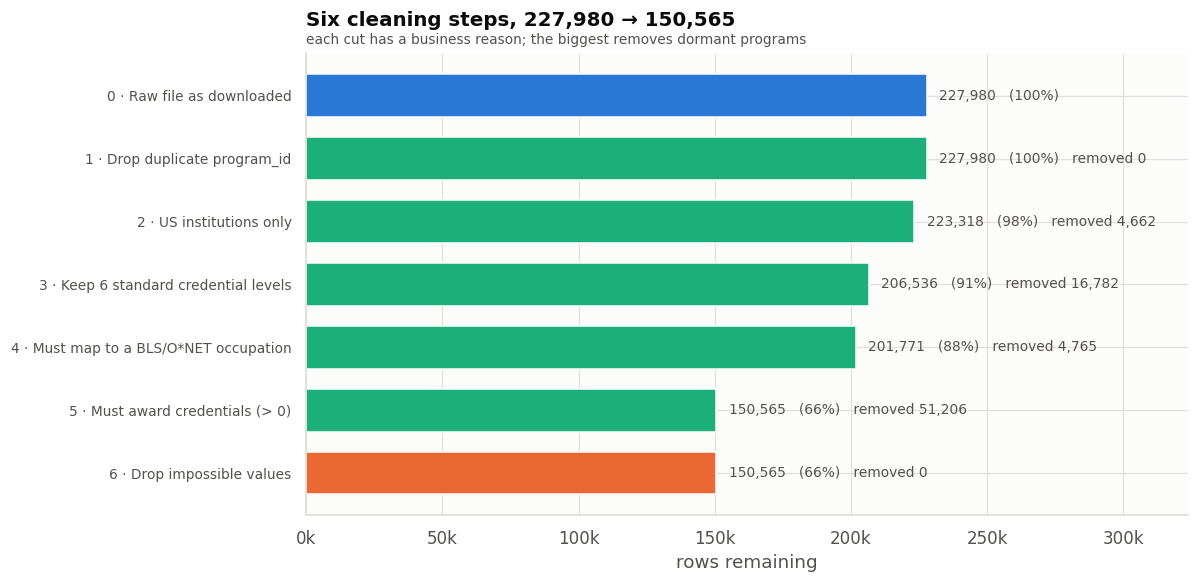

In [ ]:
fig, ax = plt.subplots(figsize=(11, 5.4))
y = range(len(fun))[::-1]
ax.barh(list(y), fun["rows"], color=[CAT[0]] + [CAT[2]]*5 + [CAT[1]], height=0.68)
ax.set_yticks(list(y)); ax.set_yticklabels(fun["step"], fontsize=9)
for yy, (r, k, n) in zip(y, zip(fun["rows"], fun["kept_%"], fun["note"])):
    ax.annotate(f"{r:,}   ({k:.0f}%)" + (f"   {n}" if n else ""),
                (r, yy), xytext=(8, 0), textcoords="offset points",
                va="center", color=INK2, fontsize=9)
ax.set_xlim(0, fun["rows"].max() * 1.42)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:,.0f}k"))
finish(ax, "Six cleaning steps, 227,980 → 150,565",
       "each cut has a business reason; the biggest removes dormant programs",
       "rows remaining", "")
plt.tight_layout(); plt.show()

**Read this chart.** We keep 66% of rows. Step 5 alone removes 51,206 — programs that awarded
nothing in the most recent year. Those are not programs academic leadership is deciding about; they are
programs that already stopped.

**So what.** After filtering, the share with reported earnings rises from 25.5% to 33.4%, because
the dormant programs we removed were disproportionately suppressed ones. The frame still covers
5.22 million credentials awarded.

---
# 5 · The column split — why the 72 columns divide themselves in two

We applied a single test to every column:

> **Does this column have a value for the ~100,000 suppressed programs?**

The whole point of the model is to score those hidden programs. Any column that is blank for
them cannot be an input, however predictive it looks.

In [ ]:
sup_mask = d["earnings_4yr_status"].eq("privacy_suppressed")

ID_COLS = ["program_id","unitid","opeid6","institution_name","institution_city",
           "institution_latitude","institution_longitude","cip_code_4digit","cip_family_code",
           "cip_title","largest_linked_occupation","largest_linked_occupation_soc",
           "ai_tool_examples","is_main_campus","outcomes_shared_across_campuses",
           "institution_is_hbcu"]
STATUS_COLS = [c for c in d.columns if c.endswith("_status")]
OUTCOME_COLS = [c for c in d.columns
                if any(k in c for k in ["earnings","debt","payment","working",
                                        "hs_threshold","cohort_size","borrower","trajectory"])
                and c not in STATUS_COLS and not c.startswith("national_")
                and not c.startswith("occupation_median_wage")]
FEATURE_COLS = [c for c in d.columns if c not in ID_COLS + STATUS_COLS + OUTCOME_COLS]

split = pd.DataFrame([
    {"group": "① Identifiers / text / coordinates", "columns": len(ID_COLS),
     "missing_in_hidden": np.nan, "role": "Cannot be features"},
    {"group": "② Status flags", "columns": len(STATUS_COLS),
     "missing_in_hidden": np.nan, "role": "Used for grouping only"},
    {"group": "③ Outcome columns", "columns": len(OUTCOME_COLS),
     "missing_in_hidden": d.loc[sup_mask, OUTCOME_COLS].isna().mean().mean()*100,
     "role": "What we predict"},
    {"group": "④ Usable features", "columns": len(FEATURE_COLS),
     "missing_in_hidden": d.loc[sup_mask, FEATURE_COLS].isna().mean().mean()*100,
     "role": "The inputs"},
])
print(split.round(1).to_string(index=False))
print("\nOutcome columns - missing rate among the hidden programs:")
print((d.loc[sup_mask, OUTCOME_COLS].isna().mean()*100).sort_values(ascending=False)
        .head(8).round(1).to_string())
print("\nFeature columns - missing rate among the hidden programs:")
print((d.loc[sup_mask, FEATURE_COLS].isna().mean()*100).sort_values()
        .head(10).round(1).to_string())

                             group  columns  missing_in_hidden                   role
① Identifiers / text / coordinates       16                NaN     Cannot be features
                    ② Status flags        4                NaN Used for grouping only
                 ③ Outcome columns       21               94.4        What we predict
                 ④ Usable features       32                7.0             The inputs

Outcome columns - missing rate among the hidden programs:
median_earnings_4yr_usd           100.0
earnings_cohort_size_4yr          100.0
earnings_vs_national_pct          100.0
debt_to_earnings_4yr              100.0
earnings_growth_pct_1yr_to_5yr     98.9
earnings_trajectory_category       98.9
debt_to_earnings_1yr               98.0
payment_to_income_pct_1yr          98.0

Feature columns - missing rate among the hidden programs:
institution_control                     0.0
credential_name                         0.0
credential_level                        0.0


**Read this.** The split is almost perfectly clean: outcome columns are 94-100% missing for
hidden programs; feature columns are 0-5% missing. There is nothing in between.

**So what.** That is not our design — **it is the shape of the privacy rule**. The Department
suppresses *how graduates turned out* (earnings, debt, employment, repayment) and publishes
*what the program is* (institution, credential, field, destination occupation). We simply cut
along that seam, and that is precisely why a model trained on the visible quarter can score
the invisible three-quarters.

## 5.2 Three kinds of missing, three mechanisms

`not_available` is a different thing from `privacy_suppressed` — the first means the Department
never collected it that cycle, the second means it was collected and withheld. Treating them
identically would blur a real distinction.

In [ ]:
miss_kinds = pd.DataFrame({
    c: d[c].value_counts() for c in ["earnings_4yr_status","earnings_1yr_status",
                                     "earnings_5yr_status","debt_status"]
}).fillna(0).astype(int)
print(miss_kinds.to_string())

ana    = d[d["earnings_4yr_status"].eq("reported")].copy()
hidden = d[d["earnings_4yr_status"].eq("privacy_suppressed")].copy()
print(f"\nAnalysis frame (reported)  : {len(ana):,}  ({len(ana)/len(d)*100:.1f}%)")
print(f"Prediction frame (suppressed): {len(hidden):,}  ({len(hidden)/len(d)*100:.1f}%)")
print(f"\nMedian credentials awarded - reported {ana['awards_year2'].median():.0f} "
      f"vs suppressed {hidden['awards_year2'].median():.0f}")
print(f"Suppressed share of all credentials awarded: "
      f"{hidden['awards_year2'].sum()/d['awards_year2'].sum()*100:.1f}%")

                    earnings_4yr_status  earnings_1yr_status  earnings_5yr_status  debt_status
not_available                         0                 6628                 6628        10478
privacy_suppressed               100336                97833               100851        98786
reported                          50229                46104                43086        41301

Analysis frame (reported)  : 50,229  (33.4%)
Prediction frame (suppressed): 100,336  (66.6%)

Median credentials awarded - reported 35 vs suppressed 6
Suppressed share of all credentials awarded: 29.3%


**Key decision: we do no imputation on the target.** Suppression is not random — reported
programs award a median of 33 credentials against 6 for suppressed ones. Filling those values
with a median would be fabricating data at the exact point where the data is most different.
Instead the suppressed rows become a **prediction set** (§12).

---
# 6 · Outliers — flag them, keep them, and test the decision

The brief asks explicitly whether including outliers leads to biased conclusions. That deserves
an experiment, not an assertion.

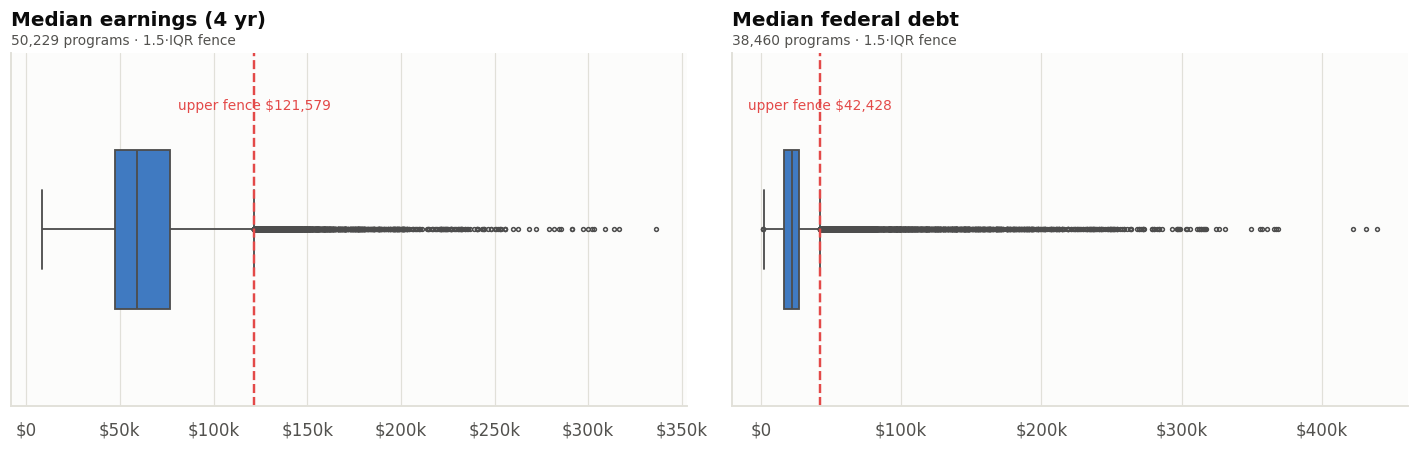

Earnings outliers: 2,001 (4.0%)
Debt outliers    : 3,272 (6.5%)
Any outlier      : 4,482 (8.9%)


In [ ]:
def iqr_flags(s, k=1.5):
    q1, q3 = s.quantile([0.25, 0.75]); iqr = q3 - q1
    return (s < q1 - k*iqr) | (s > q3 + k*iqr), (q1 - k*iqr, q3 + k*iqr)

ana["earn_outlier"], earn_fence = iqr_flags(ana["median_earnings_4yr_usd"])
ana["debt_outlier"], debt_fence = iqr_flags(ana["median_debt_usd"])
ana["any_outlier"] = ana["earn_outlier"] | ana["debt_outlier"]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, col, fence, name in [
        (axes[0], "median_earnings_4yr_usd", earn_fence, "Median earnings (4 yr)"),
        (axes[1], "median_debt_usd",         debt_fence, "Median federal debt")]:
    sns.boxplot(x=ana[col], ax=ax, color=CAT[0], width=0.45, fliersize=2.5, linewidth=1.2)
    ax.axvline(fence[1], color=CAT[7], ls="--", lw=1.6)
    ax.annotate(f"upper fence ${fence[1]:,.0f}", (fence[1], -0.34),
                color=CAT[7], fontsize=9, ha="center")
    ax.xaxis.set_major_formatter(USD)
    finish(ax, name, f"{ana[col].notna().sum():,} programs · 1.5·IQR fence", "", "")
plt.tight_layout(); plt.show()

print(f"Earnings outliers: {ana['earn_outlier'].sum():,} ({ana['earn_outlier'].mean()*100:.1f}%)")
print(f"Debt outliers    : {ana['debt_outlier'].sum():,} ({ana['debt_outlier'].mean()*100:.1f}%)")
print(f"Any outlier      : {ana['any_outlier'].sum():,} ({ana['any_outlier'].mean()*100:.1f}%)")

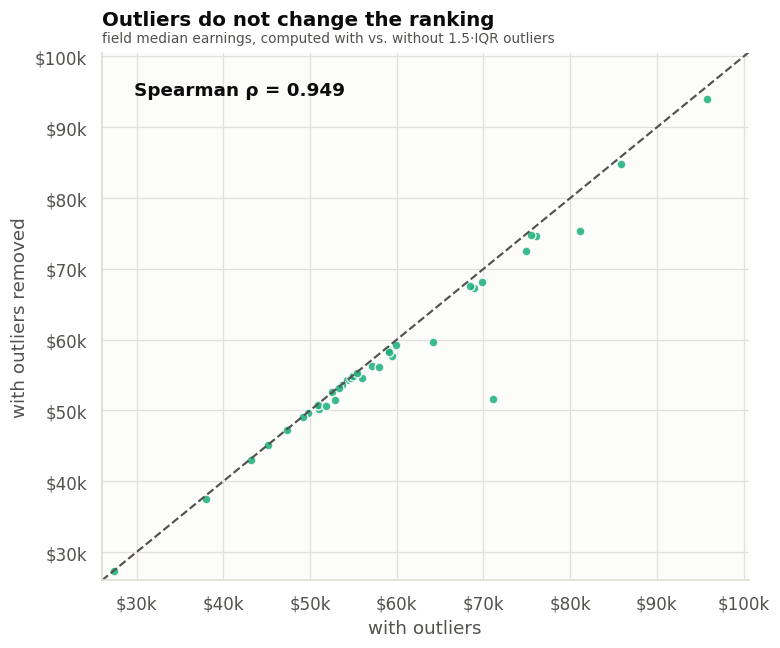

Spearman rank correlation of the 49 field rankings: 0.9490


In [ ]:
def field_medians(frame):
    return frame.groupby("cip_family_title", observed=True)["median_earnings_4yr_usd"].median()

with_o, without_o = field_medians(ana), field_medians(ana[~ana["any_outlier"]])
cmp = pd.concat([with_o.rename("with"), without_o.rename("without")], axis=1).dropna()
rho = cmp["with"].corr(cmp["without"], method="spearman")

fig, ax = plt.subplots(figsize=(7.2, 6))
ax.scatter(cmp["with"], cmp["without"], s=34, color=CAT[2], alpha=0.85, edgecolors="white")
lim = [cmp.min().min()*0.95, cmp.max().max()*1.05]
ax.plot(lim, lim, ls="--", color=INK2, lw=1.4)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.xaxis.set_major_formatter(USD); ax.yaxis.set_major_formatter(USD)
ax.annotate(f"Spearman ρ = {rho:.3f}", xy=(0.05, 0.92), xycoords="axes fraction",
            fontsize=12, color=INK, fontweight="bold")
finish(ax, "Outliers do not change the ranking",
       "field median earnings, computed with vs. without 1.5·IQR outliers",
       "with outliers", "with outliers removed")
plt.tight_layout(); plt.show()
print(f"Spearman rank correlation of the 49 field rankings: {rho:.4f}")

**Read this chart.** Every field sits on the diagonal; the rank correlation is ρ ≈ 0.94.

**So what.** We **keep** the outliers. Medical, dental and law programs really do pay
six figures — they are the signal, not noise. Removing them would delete the top of the
distribution academic leadership most needs to see, and the experiment shows it would buy nothing.

---
# 7 · Feature engineering

Four constructed metrics. Two of them are corrections of formulas we got wrong in an earlier
pass — both bugs are documented below, because catching them is part of the analysis.

In [ ]:
# ── AI exposure index ────────────────────────────────────────────────────────
# FIX #1: scale ONCE across the whole frame. An earlier version min-max scaled the
# reported and hidden frames separately, so 0.5 did not mean the same thing on each
# side and the relationship learned on reported data was misaligned on hidden data.
AI_SIGNALS = ["ai_software_occupation_share", "expert_system_occupation_share",
              "ai_tools_max_per_occupation", "hot_technologies_mean_per_occupation"]

def minmax(s):
    lo, hi = s.min(), s.max()
    return (s - lo) / (hi - lo) if hi > lo else s * 0

d["ai_exposure_index"] = pd.DataFrame({c: minmax(d[c]) for c in AI_SIGNALS}).mean(axis=1)
ana["ai_exposure_index"]    = d.loc[ana.index,    "ai_exposure_index"]
hidden["ai_exposure_index"] = d.loc[hidden.index, "ai_exposure_index"]

# ── wage catch-up ────────────────────────────────────────────────────────────
# FIX #2: use a RATIO, not a difference. The old version subtracted the BLS
# whole-career median wage from 4-year-out earnings and reported -27%, which reads
# as "every program underperforms the market". It was comparing early career against
# mid career. As a ratio it means something real.
for f in (d, ana, hidden):
    f["wage_catchup_pct"] = f["median_earnings_4yr_usd"] / f["occupation_median_wage_2024_usd"] * 100
    f["pay_vs_national_pct"] = (f["median_earnings_4yr_usd"]
                                / f["national_median_earnings_4yr_usd"] - 1) * 100
    f["annual_debt_burden"] = f["median_monthly_payment_usd"] * 12 / f["median_earnings_4yr_usd"]

# ── ROI tier ─────────────────────────────────────────────────────────────────
TIER_BINS   = [-0.001, 0.30, 0.60, 1.00, np.inf]
TIER_LABELS = ["Strong (<0.30)", "Moderate (0.30-0.60)",
               "Stretched (0.60-1.00)", "At risk (>1.00)"]
TIER_COLORS = {"Strong (<0.30)": "#0ca30c", "Moderate (0.30-0.60)": "#2a78d6",
               "Stretched (0.60-1.00)": "#eda100", "At risk (>1.00)": "#d03b3b"}
for f in (d, ana):
    f["roi_tier"] = pd.cut(f["debt_to_earnings_4yr"], bins=TIER_BINS, labels=TIER_LABELS)

print(ana[["ai_exposure_index", "wage_catchup_pct", "pay_vs_national_pct",
           "annual_debt_burden"]].describe().T.round(3).to_string())

n_tier = ana["roi_tier"].notna().sum()
print(f"\nROI tier — DENOMINATOR MATTERS: only {n_tier:,} rows have both debt and earnings")
print(f"  that is {n_tier/len(d)*100:.1f}% of the {len(d):,}-row analysis frame")
print((ana["roi_tier"].value_counts().reindex(TIER_LABELS).to_frame("programs")
       .assign(**{"% of the {:,} with data".format(n_tier):
                  lambda t: (t["programs"]/n_tier*100).round(1)})).to_string())

                       count    mean     std     min     25%     50%     75%      max
ai_exposure_index    48736.0   0.104   0.157   0.000   0.010   0.031   0.150    0.769
wage_catchup_pct     50229.0  76.633  28.388  13.654  57.231  73.057  90.652  451.772
pay_vs_national_pct  50228.0   1.037  21.046 -78.299 -10.819  -0.920  10.309  363.981
annual_debt_burden   38460.0   0.053   0.037   0.004   0.033   0.046   0.063    0.786

ROI tier — DENOMINATOR MATTERS: only 38,460 rows have both debt and earnings
  that is 25.5% of the 150,565-row analysis frame
                       programs  % of the 38,460 with data
roi_tier                                                  
Strong (<0.30)            13934                       36.2
Moderate (0.30-0.60)      19641                       51.1
Stretched (0.60-1.00)      3752                        9.8
At risk (>1.00)            1133                        2.9


| Metric | Formula | Note |
|---|---|---|
| `ai_exposure_index` | four O\*NET signals min-max scaled to 0-1, then averaged | **scaled once across all rows** (bug fix #1) |
| `wage_catchup_pct` | program earnings ÷ occupation median wage × 100 | a ratio, not a difference (bug fix #2) |
| `pay_vs_national_pct` | earnings ÷ national median for the same field+credential − 1 | the official benchmark |
| `annual_debt_burden` | annual loan payment ÷ earnings | affordability |
| `roi_tier` | debt-to-earnings, banded into four | **state the denominator whenever quoting these percentages** |

⚠️ **The ROI-tier denominator is a real trap.** Debt-to-earnings exists for only ~19% of the
analysis frame. "3.5% at risk" means 3.5% *of programs with both debt and earnings data*, not
3.5% of the catalogue. Every slide quoting it must say so.

---
# 8 · Exploration, layer 1 — what the target looks like

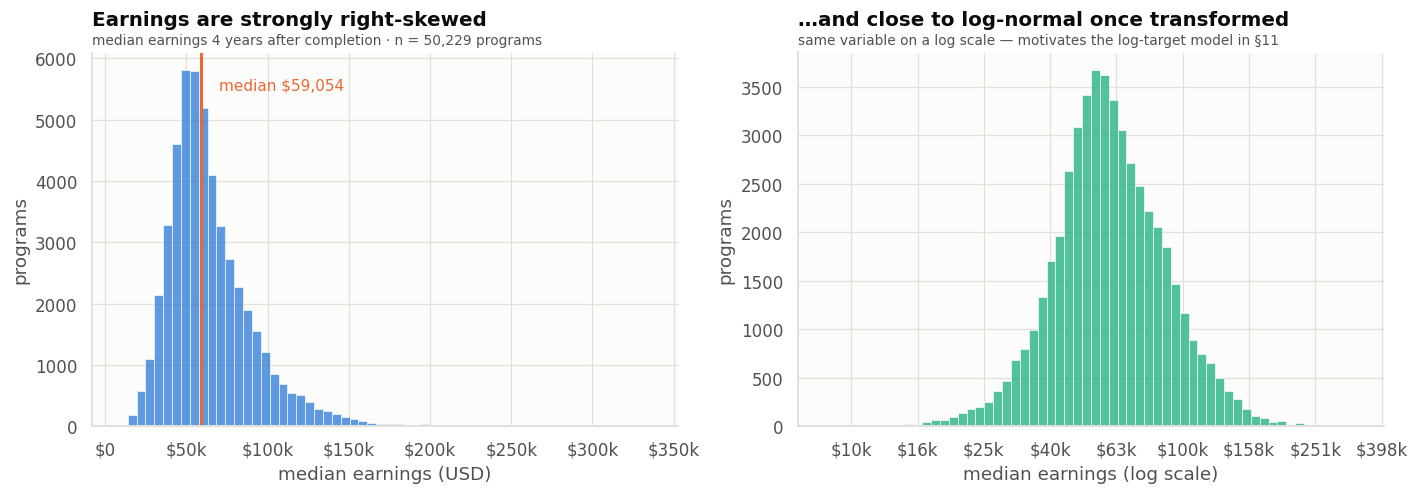

Skew (raw): 1.68   Skew (log): 0.02
Quartiles: $47,229 / $59,054 / $76,969


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.6))
e = ana["median_earnings_4yr_usd"].dropna()

sns.histplot(e, bins=60, color=CAT[0], ax=axes[0], edgecolor="white", linewidth=0.4)
axes[0].axvline(e.median(), color=CAT[1], lw=2)
axes[0].annotate(f"median ${e.median():,.0f}", (e.median(), axes[0].get_ylim()[1]*0.9),
                 xytext=(12, 0), textcoords="offset points", color=CAT[1], fontsize=10)
axes[0].xaxis.set_major_formatter(USD)
finish(axes[0], "Earnings are strongly right-skewed",
       f"median earnings 4 years after completion · n = {len(e):,} programs",
       "median earnings (USD)", "programs")

sns.histplot(np.log10(e), bins=60, color=CAT[2], ax=axes[1], edgecolor="white", linewidth=0.4)
axes[1].xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"${10**v/1000:,.0f}k"))
finish(axes[1], "…and close to log-normal once transformed",
       "same variable on a log scale — motivates the log-target model in §11",
       "median earnings (log scale)", "programs")
plt.tight_layout(); plt.show()

print(f"Skew (raw): {e.skew():.2f}   Skew (log): {np.log(e).skew():.2f}")
print(f"Quartiles: ${e.quantile(.25):,.0f} / ${e.median():,.0f} / ${e.quantile(.75):,.0f}")

**Read this chart.** Raw skew 1.76, log skew 0.02. **So what:** a linear model on the raw
target will systematically under-predict the long right tail — which is exactly what §11 finds,
and why a log-target rung sits in the model ladder.

## 8.2 The credential ladder — the steepest single gradient

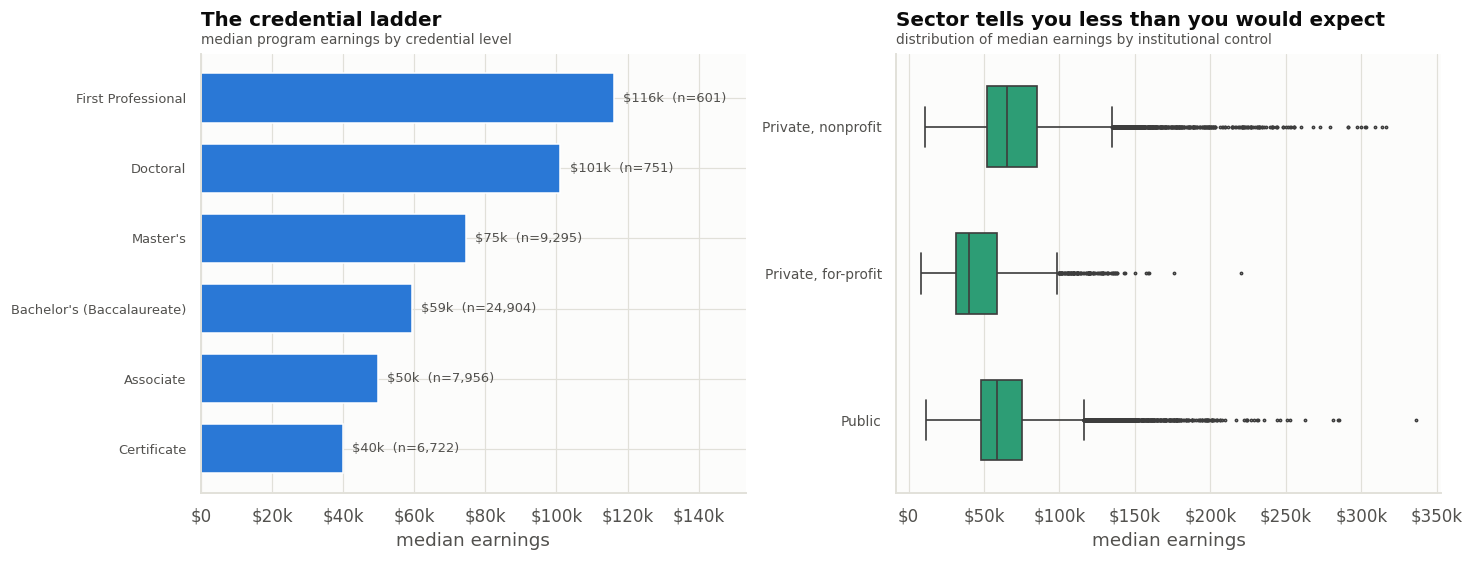

Bottom-to-top spread: 2.9x


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 5.2))

cred = (ana.groupby("degree_level_6", observed=True)
           .agg(n=("program_id", "size"), med=("median_earnings_4yr_usd", "median"))
           .sort_values("med"))
axes[0].barh(cred.index, cred["med"], color=CAT[0], height=0.7)
for y, (n, m) in enumerate(zip(cred["n"], cred["med"])):
    axes[0].annotate(f"${m/1000:,.0f}k  (n={n:,})", (m, y), xytext=(6, 0),
                     textcoords="offset points", va="center", color=INK2, fontsize=8.5)
axes[0].xaxis.set_major_formatter(USD)
axes[0].set_xlim(0, cred["med"].max()*1.32)
axes[0].tick_params(axis="y", labelsize=8.5)
finish(axes[0], "The credential ladder", "median program earnings by credential level",
       "median earnings", "")

sns.boxplot(data=ana, y="institution_control", x="median_earnings_4yr_usd",
            ax=axes[1], color=CAT[2], width=0.55, fliersize=1.5, linewidth=1.1)
axes[1].xaxis.set_major_formatter(USD)
axes[1].tick_params(axis="y", labelsize=9)
finish(axes[1], "Sector tells you less than you would expect",
       "distribution of median earnings by institutional control", "median earnings", "")
plt.tight_layout(); plt.show()

print(f"Bottom-to-top spread: {cred['med'].max()/cred['med'].min():.1f}x")

**Read this chart.** Certificate → First Professional is roughly a 2.9x spread, and the rungs
are cleanly ordered. The right panel is the contrast: public, private-nonprofit and for-profit
medians overlap heavily.

**So what.** Credential level is a far stronger signal than institutional sector — which the
model confirms independently in §11.

## 8.3 Field of study — a $65k spread end to end

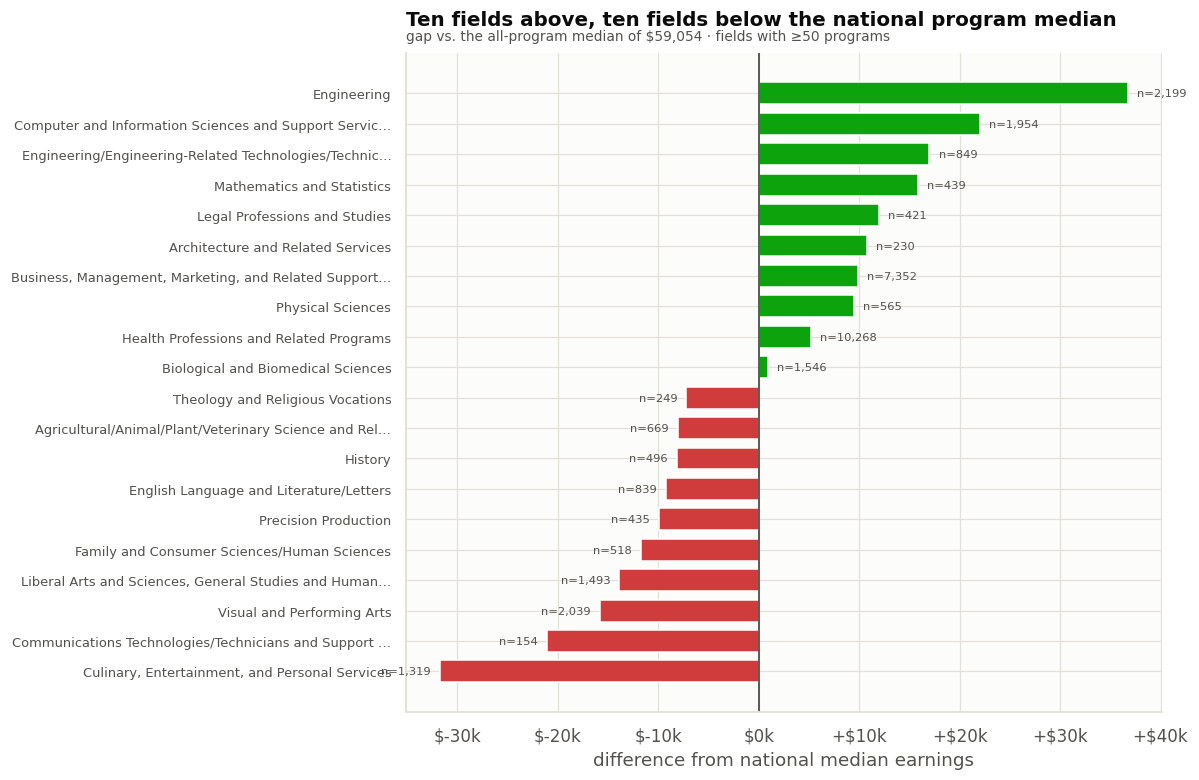

Top:    Engineering  $95,775  (+36,721)
Bottom: Culinary, Entertainment, and Personal Services  $27,366  (-31,688)
End-to-end spread: $68,409


In [ ]:
fam = (ana.groupby("cip_family_title", observed=True)
          .agg(n=("program_id", "size"), grads=("awards_year2", "sum"),
               earn=("median_earnings_4yr_usd", "median"),
               debt=("median_debt_usd", "median"))
          .query("n >= 50"))
national = ana["median_earnings_4yr_usd"].median()
fam["gap"] = fam["earn"] - national
fam = fam.sort_values("gap")
show = pd.concat([fam.head(10), fam.tail(10)])

fig, ax = plt.subplots(figsize=(11, 7.2))
cols = [("#d03b3b" if g < 0 else "#0ca30c") for g in show["gap"]]
ax.barh(range(len(show)), show["gap"], color=cols, height=0.72)
ax.set_yticks(range(len(show)))
ax.set_yticklabels([t[:52] + ("…" if len(t) > 52 else "") for t in show.index], fontsize=8.5)
ax.axvline(0, color=INK2, lw=1.2)
ax.xaxis.set_major_formatter(mtick.FuncFormatter(
    lambda v, _: f"{'+' if v>0 else ''}${v/1000:,.0f}k"))
for y, (g, n) in enumerate(zip(show["gap"], show["n"])):
    ax.annotate(f"n={n:,}", (g, y), xytext=(6 if g > 0 else -6, 0),
                textcoords="offset points", va="center",
                ha="left" if g > 0 else "right", color=INK2, fontsize=7.5)
finish(ax, "Ten fields above, ten fields below the national program median",
       f"gap vs. the all-program median of ${national:,.0f} · fields with ≥50 programs",
       "difference from national median earnings", "")
plt.tight_layout(); plt.show()

print(f"Top:    {fam.index[-1][:50]}  ${fam['earn'].iloc[-1]:,.0f}  ({fam['gap'].iloc[-1]:+,.0f})")
print(f"Bottom: {fam.index[0][:50]}  ${fam['earn'].iloc[0]:,.0f}  ({fam['gap'].iloc[0]:+,.0f})")
print(f"End-to-end spread: ${fam['earn'].max()-fam['earn'].min():,.0f}")

**Read this chart.** Engineering sits about +$36k above the all-program median; Culinary and
Personal Services about −$32k below. These are not niche categories — the n labels show tens of
thousands of programs on both ends.

**So what.** Field choice moves the outcome by more than any institutional characteristic we
measure. §11 quantifies this: Engineering carries a +$22,721 coefficient while Visual and
Performing Arts carries −$17,265 — a $40,000 swing at the same school, same credential.

## 8.4 Field x credential — the interaction that breaks a single linear model

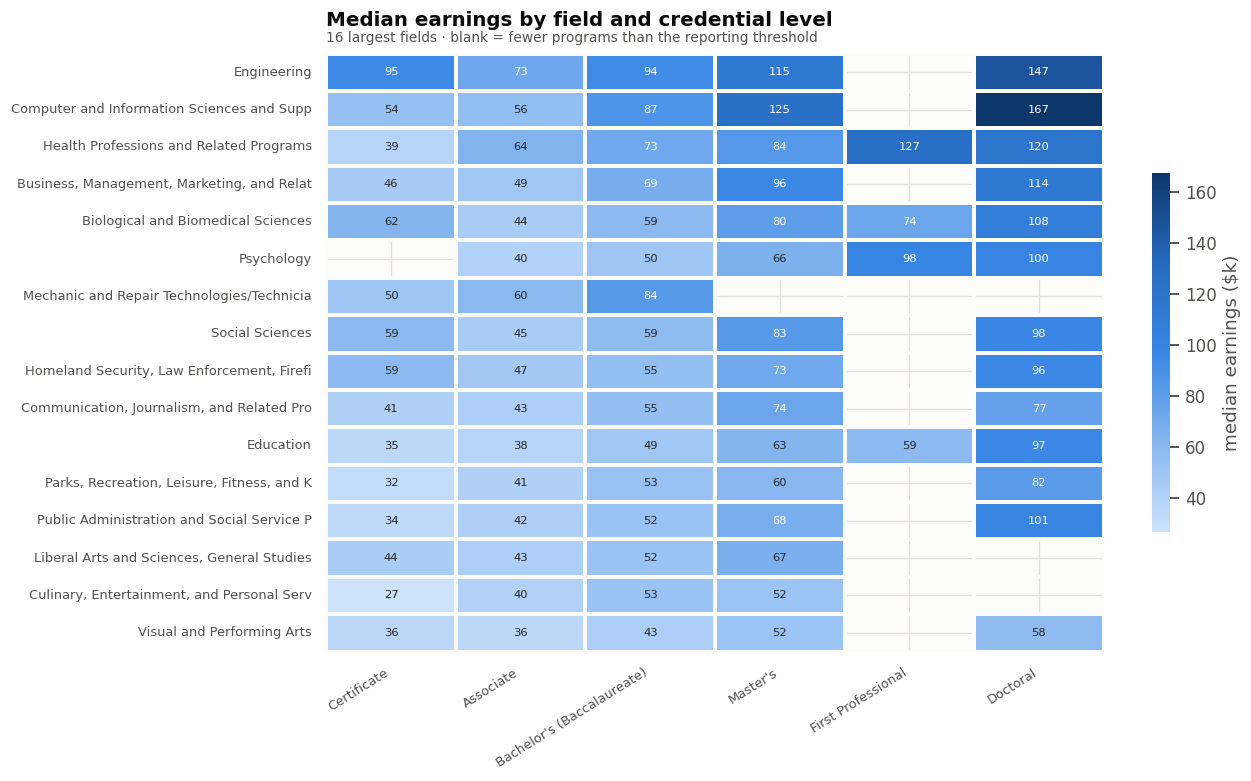

Computer and Information Sciences and Support Se   bachelor→master: +37,710
Visual and Performing Arts                         bachelor→master: +8,700


In [ ]:
top_fams = ana["cip_family_title"].value_counts().head(16).index
cred_order = DEGREE_LEVEL_ORDER
pivot = (ana[ana["cip_family_title"].isin(top_fams)]
         .pivot_table(index="cip_family_title", columns="degree_level_6",
                      values="median_earnings_4yr_usd", aggfunc="median", observed=True)
         .reindex(columns=[c for c in cred_order if c in ana["degree_level_6"].unique()]))
pivot = pivot.loc[pivot.median(axis=1).sort_values(ascending=False).index].dropna(axis=1, how="all")

fig, ax = plt.subplots(figsize=(12, 7.2))
sns.heatmap(pivot/1000, cmap=SEQ, annot=True, fmt=".0f", annot_kws={"size": 7.5},
            linewidths=1.6, linecolor=SURFACE,
            cbar_kws={"shrink": 0.6, "label": "median earnings ($k)"}, ax=ax)
ax.set_yticklabels([t.get_text()[:42] for t in ax.get_yticklabels()], fontsize=8.5, rotation=0)
ax.set_xticklabels([t.get_text()[:26] for t in ax.get_xticklabels()],
                   fontsize=8.5, rotation=32, ha="right")
finish(ax, "Median earnings by field and credential level",
       "16 largest fields · blank = fewer programs than the reporting threshold", "", "")
plt.tight_layout(); plt.show()

def jump(field, a="Bachelor's (Baccalaureate)", b="Master's"):
    try:
        return pivot.loc[field, b] - pivot.loc[field, a]
    except Exception:
        return np.nan
for f in ["Computer and Information Sciences and Support Services", "Visual and Performing Arts"]:
    if f in pivot.index:
        print(f"{f[:48]:50s} bachelor→master: {jump(f):+,.0f}")

**Read this chart.** Reading across a row shows what one more rung is worth *inside* that
field. The rows are not parallel — that is the whole point.

**So what.** This is a textbook **interaction**, and it is the single reason a plain linear model
cannot be the final answer. Linear regression is forced to give one number for "the value of a
master's" across every field; §11.4 splits the regression by field group and §11.5 lets a tree
discover the same thing automatically.

---
# 9 · AI exposure — define it, test it, then invert the expected conclusion

This is the section the whole project is named for, so it gets its own three-part treatment.

## 9.1 Definition

AI exposure measures **how far AI tools have already entered the day-to-day work of the
occupations a program feeds**. The data comes from O\*NET, the U.S. Department of Labor's
occupational database, which records the software each occupation actually uses.

| Signal | Meaning |
|---|---|
| `ai_software_occupation_share` | share of linked occupations that list AI software |
| `expert_system_occupation_share` | share that list expert systems |
| `ai_tools_max_per_occupation` | most distinct AI tools listed for any one linked occupation |
| `hot_technologies_mean_per_occupation` | mean count of O\*NET "hot technologies" |

Each is min-max scaled to 0-1, then averaged.

> ### Say this before anything else
> **"Exposure" does not mean "will be replaced."** O\*NET records which tools are *present* in a
> job, not whether the job will disappear. High exposure means precisely: **AI has already
> entered the workflow of that occupation.**

In [ ]:
print(ana["ai_exposure_index"].describe(percentiles=[.25,.5,.75,.9]).round(3).to_string())

count    48736.000
mean         0.104
std          0.157
min          0.000
25%          0.010
50%          0.031
75%          0.150
90%          0.270
max          0.769


## 9.2 Where AI exposure sits relative to pay

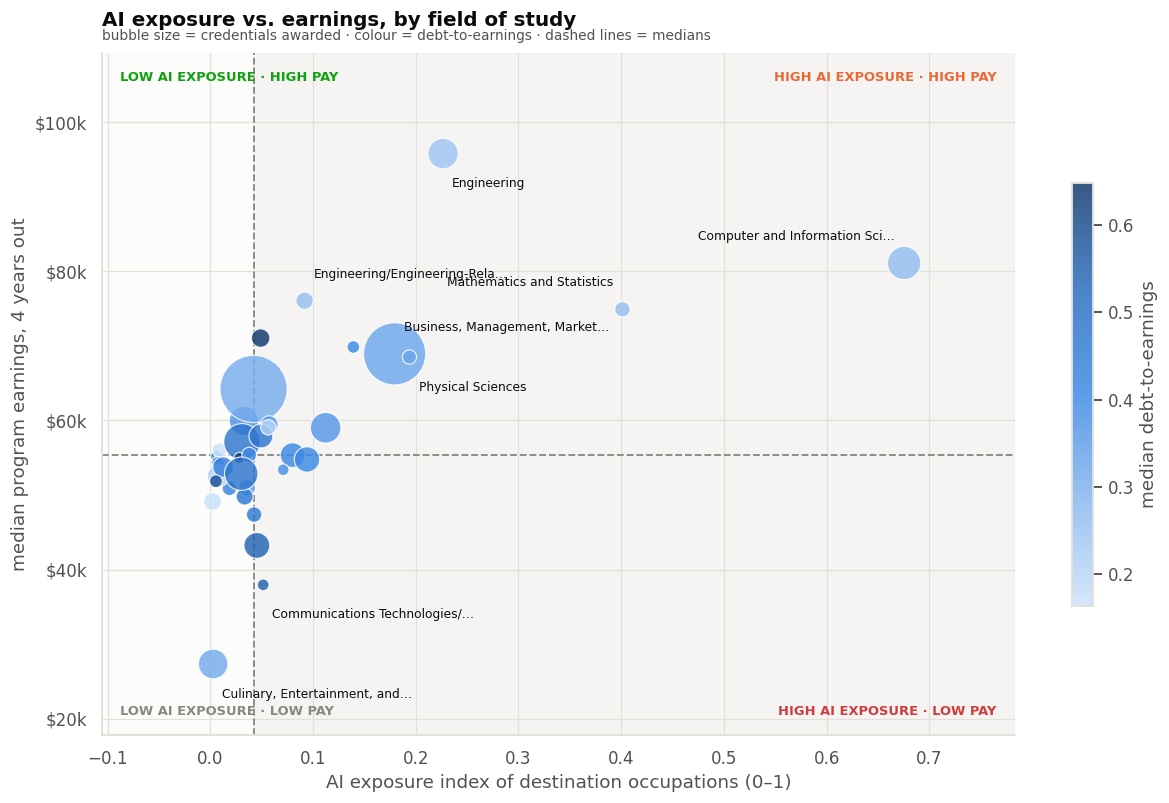

Fields in the 'high pay, high AI exposure' quadrant: 12 of 35
They account for 40.2% of all credentials awarded.
Pearson r(AI exposure, 4-year earnings) across fields = +0.638


In [ ]:
q = (ana.groupby("cip_family_title", observed=True)
        .agg(earn=("median_earnings_4yr_usd", "median"), ai=("ai_exposure_index", "mean"),
             grads=("awards_year2", "sum"), n=("program_id", "size"),
             de=("debt_to_earnings_4yr", "median"))
        .query("n >= 50").dropna(subset=["ai", "earn"]))
xm, ym = q["ai"].median(), q["earn"].median()

fig, ax = plt.subplots(figsize=(11.5, 7.4))
xpad = (q["ai"].max()-q["ai"].min())*0.16 or 0.02
ypad = (q["earn"].max()-q["earn"].min())*0.14 or 1000
xlo, xhi = q["ai"].min()-xpad, q["ai"].max()+xpad
ylo, yhi = q["earn"].min()-ypad, q["earn"].max()+ypad*1.4
ax.set_xlim(xlo, xhi); ax.set_ylim(ylo, yhi)
ax.axvspan(xm, xhi, color="#f0efec", alpha=0.55, zorder=0)
ax.axvline(xm, color=MUTED, ls="--", lw=1.2, zorder=1)
ax.axhline(ym, color=MUTED, ls="--", lw=1.2, zorder=1)

sizes = 40 + 1900*(q["grads"]/q["grads"].max())
sc = ax.scatter(q["ai"], q["earn"], s=sizes, c=q["de"], cmap=SEQ,
                alpha=0.82, edgecolors="white", linewidths=0.8, zorder=3)
cb = plt.colorbar(sc, ax=ax, shrink=0.62); cb.set_label("median debt-to-earnings", color=INK2)

qq = q.assign(_d=((q["ai"]-xm)/q["ai"].std())**2 + ((q["earn"]-ym)/q["earn"].std())**2)
for k, (name, row) in enumerate(qq.nlargest(8, "_d").iterrows()):
    dy = 15 if k % 2 == 0 else -22
    ha = "left" if row["ai"] < (xlo+xhi)/2 else "right"
    ax.annotate(name[:28] + ("…" if len(name) > 28 else ""), (row["ai"], row["earn"]),
                xytext=(6 if ha == "left" else -6, dy), textcoords="offset points",
                ha=ha, fontsize=8, color=INK, zorder=4)
for txt, xy, col in [("LOW AI EXPOSURE · HIGH PAY", (0.02, 0.96), "#0ca30c"),
                     ("HIGH AI EXPOSURE · HIGH PAY", (0.98, 0.96), "#eb6834"),
                     ("LOW AI EXPOSURE · LOW PAY", (0.02, 0.03), MUTED),
                     ("HIGH AI EXPOSURE · LOW PAY", (0.98, 0.03), "#d03b3b")]:
    ax.annotate(txt, xy=xy, xycoords="axes fraction", fontsize=8.5, color=col,
                fontweight="bold", ha="left" if xy[0] < .5 else "right")
ax.yaxis.set_major_formatter(USD)
finish(ax, "AI exposure vs. earnings, by field of study",
       "bubble size = credentials awarded · colour = debt-to-earnings · dashed lines = medians",
       "AI exposure index of destination occupations (0–1)", "median program earnings, 4 years out")
plt.tight_layout(); plt.show()

hi_hi = q[(q["ai"] > xm) & (q["earn"] > ym)]
print(f"Fields in the 'high pay, high AI exposure' quadrant: {len(hi_hi)} of {len(q)}")
print(f"They account for {hi_hi['grads'].sum()/q['grads'].sum()*100:.1f}% of all credentials awarded.")
print(f"Pearson r(AI exposure, 4-year earnings) across fields = {q['ai'].corr(q['earn']):+.3f}")

**Read this chart.** The high-pay quadrant is the *right*-hand one. Computer Science,
Mathematics, Engineering and Business — the fields with the most AI tooling in their destination
occupations — are also the best-paid.

**So what.** At the field level, AI exposure and four-year earnings move together. That
relationship may reflect differences between fields, so §9.3 compares programs within
early-career pay bands before comparing their later growth.

## 9.3 The real test — do programs with similar pay today diverge over time?

A cross-sectional correlation cannot answer the question university leadership is actually asking.
Because the outcome is 1→5-year earnings growth, we use `median_earnings_1yr_usd` as the
starting-pay measure. We match programs within early-career pay bands, then compare the
bottom and top quartile of AI exposure. This is a descriptive screening test, not a causal
estimate.

> The table below is generated from the current cleaned row universe and reports both the
> growth difference and the starting-pay gap for each band.

In [ ]:
START_PAY = "median_earnings_1yr_usd"
GROWTH = "earnings_growth_pct_1yr_to_5yr"
w = ana.dropna(subset=[START_PAY, GROWTH, "ai_exposure_index"]).copy()
print(f"Programs with early-career pay, AI exposure, and 1→5 year growth: {len(w):,}")
print(f"Pearson r(AI exposure, early-career earnings) = {w['ai_exposure_index'].corr(w[START_PAY]):+.3f}")
print(f"Pearson r(AI exposure, 1→5 yr growth)          = {w['ai_exposure_index'].corr(w[GROWTH]):+.3f}")

BANDS  = [0, 40000, 50000, 60000, 70000, 85000, 110000, np.inf]
LABELS = ["<$40k", "$40–50k", "$50–60k", "$60–70k", "$70–85k", "$85–110k", ">$110k"]
w["band"] = pd.cut(w[START_PAY], BANDS, labels=LABELS)

rows = []
for b, g in w.groupby("band", observed=True):
    if len(g) < 200: continue
    lo, hi = g["ai_exposure_index"].quantile([.25, .75])
    L, H = g[g["ai_exposure_index"] <= lo], g[g["ai_exposure_index"] >= hi]
    rows.append({"band": b, "n": len(g),
                 "pay_low_AI": L[START_PAY].median(),
                 "pay_high_AI": H[START_PAY].median(),
                 "pay_gap_pct": 100 * (H[START_PAY].median() - L[START_PAY].median()) /
                                ((H[START_PAY].median() + L[START_PAY].median()) / 2),
                 "growth_low_AI": L[GROWTH].median(),
                 "growth_high_AI": H[GROWTH].median()})
band_tbl = pd.DataFrame(rows)
band_tbl["gap_pp"] = band_tbl["growth_high_AI"] - band_tbl["growth_low_AI"]
print()
print(band_tbl.round(1).to_string(index=False))
if not band_tbl.empty:
    best = band_tbl.loc[band_tbl["gap_pp"].idxmax()]
    print(f"Largest positive AI-growth gap: {best['band']} = {best['gap_pp']:+.1f} pp; "
          f"starting-pay gap = {best['pay_gap_pct']:+.1f}%")

Programs with early-career pay, AI exposure, and 1→5 year growth: 32,634
Pearson r(AI exposure, early-career earnings) = +0.233
Pearson r(AI exposure, 1→5 yr growth)          = +0.034

    band     n  pay_low_AI  pay_high_AI  pay_gap_pct  growth_low_AI  growth_high_AI  gap_pp
   <$40k 13880     26998.0      32887.0         19.7           25.2            45.4    20.2
 $40–50k  5988     44528.0      45087.0          1.2           14.2            39.3    25.0
 $50–60k  4149     54244.0      54644.0          0.7           10.6            36.0    25.4
 $60–70k  3472     65076.5      65144.0          0.1           10.7            35.0    24.3
 $70–85k  3173     75417.0      75780.5          0.5           10.3            32.5    22.2
$85–110k  1294     99000.0      93148.0         -6.1           13.5            28.8    15.3
  >$110k   678    123367.0     123979.5          0.5            9.1            24.0    15.0
Largest positive AI-growth gap: $50–60k = +25.4 pp; starting-pay gap = +0.7%


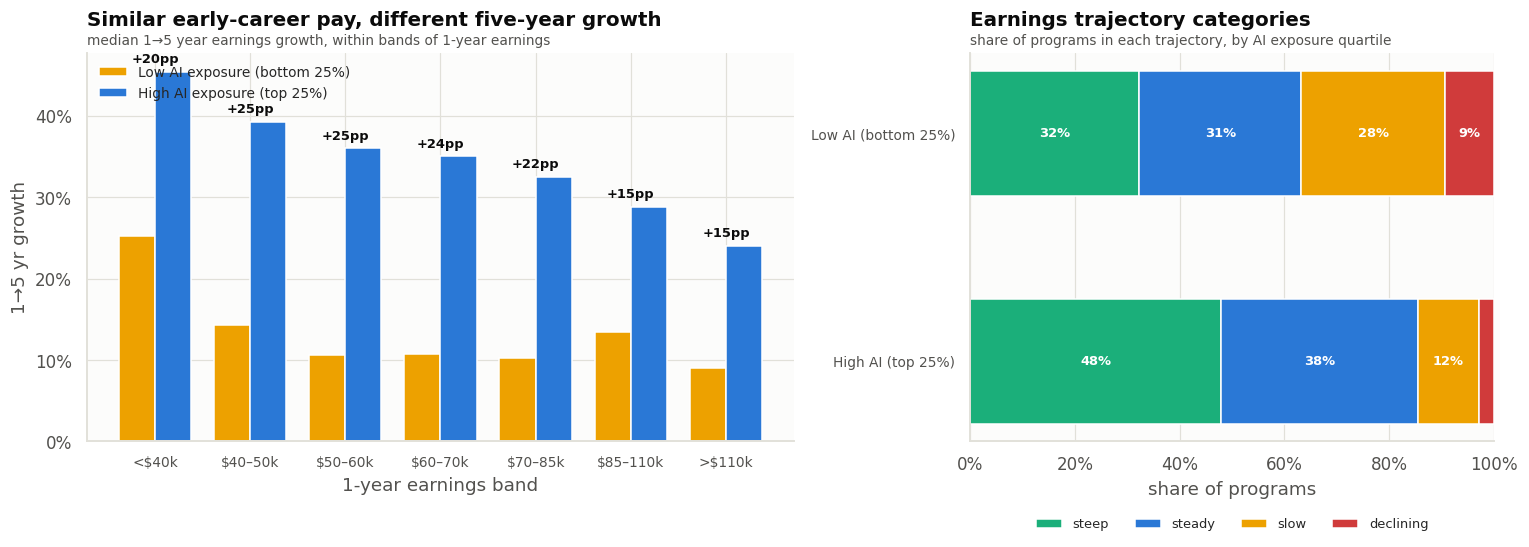

Declining: 9.3% of low-exposure programs vs 2.9% of high-exposure — a factor of 3.2x


In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5.2),
                         gridspec_kw={"width_ratios": [1.35, 1]})

x = np.arange(len(band_tbl)); wd = 0.38
axes[0].bar(x - wd/2, band_tbl["growth_low_AI"], wd, color=CAT[3], label="Low AI exposure (bottom 25%)")
axes[0].bar(x + wd/2, band_tbl["growth_high_AI"], wd, color=CAT[0], label="High AI exposure (top 25%)")
for i, r in band_tbl.iterrows():
    axes[0].annotate(f"{r['gap_pp']:+.0f}pp", (i, max(r["growth_low_AI"], r["growth_high_AI"])),
                     xytext=(0, 6), textcoords="offset points", ha="center",
                     fontsize=8.5, color=INK, fontweight="bold")
axes[0].set_xticks(x); axes[0].set_xticklabels(band_tbl["band"], fontsize=9)
axes[0].yaxis.set_major_formatter(PCT); axes[0].legend(loc="upper left", fontsize=9)
finish(axes[0], "Similar early-career pay, different five-year growth",
       "median 1→5 year earnings growth, within bands of 1-year earnings",
       "1-year earnings band", "1→5 yr growth")

traj = (w.assign(grp=np.where(w["ai_exposure_index"] >= w["ai_exposure_index"].quantile(.75),
                              "High AI (top 25%)",
                     np.where(w["ai_exposure_index"] <= w["ai_exposure_index"].quantile(.25),
                              "Low AI (bottom 25%)", None)))
          .dropna(subset=["grp", "earnings_trajectory_category"]))
order_t = ["steep", "steady", "slow", "declining"]
ct = (pd.crosstab(traj["grp"], traj["earnings_trajectory_category"], normalize="index")*100)
ct = ct.reindex(columns=[c for c in order_t if c in ct.columns])
bottom = np.zeros(len(ct))
for j, c in enumerate(ct.columns):
    axes[1].barh(ct.index, ct[c], left=bottom, height=0.55,
                 color=[CAT[2], CAT[0], CAT[3], "#d03b3b"][j], label=c)
    for i, v in enumerate(ct[c]):
        if v > 4:
            axes[1].annotate(f"{v:.0f}%", (bottom[i]+v/2, i), ha="center", va="center",
                             fontsize=8.5, color="white", fontweight="bold")
    bottom += ct[c].values
axes[1].set_xlim(0, 100); axes[1].xaxis.set_major_formatter(PCT)
axes[1].legend(loc="lower center", bbox_to_anchor=(0.5, -0.26), ncol=4, fontsize=8.5)
axes[1].tick_params(axis="y", labelsize=9)
finish(axes[1], "Earnings trajectory categories",
       "share of programs in each trajectory, by AI exposure quartile", "share of programs", "")
plt.tight_layout(); plt.show()

dec = ct["declining"] if "declining" in ct.columns else None
if dec is not None:
    lo_d, hi_d = dec.get("Low AI (bottom 25%)", np.nan), dec.get("High AI (top 25%)", np.nan)
    print(f"Declining: {lo_d:.1f}% of low-exposure programs vs {hi_d:.1f}% of high-exposure "
          f"— a factor of {lo_d/hi_d:.1f}x")

**Read these charts.** The left chart compares programs within 1-year earnings bands. Use
`pay_gap_pct` in the table to check that the low- and high-exposure groups start near the same
pay; cell 47 prints the band with the largest positive growth gap. The right chart is an
overall trajectory summary by AI exposure, not a pay-matched comparison.

**So what.** Overall program-level AI–growth correlation is near zero (r ≈ +0.03), while AI
exposure and early-career pay are correlated. The banded result is an association, not proof
that AI causes earnings growth.

## 9.4 Three matched pairs

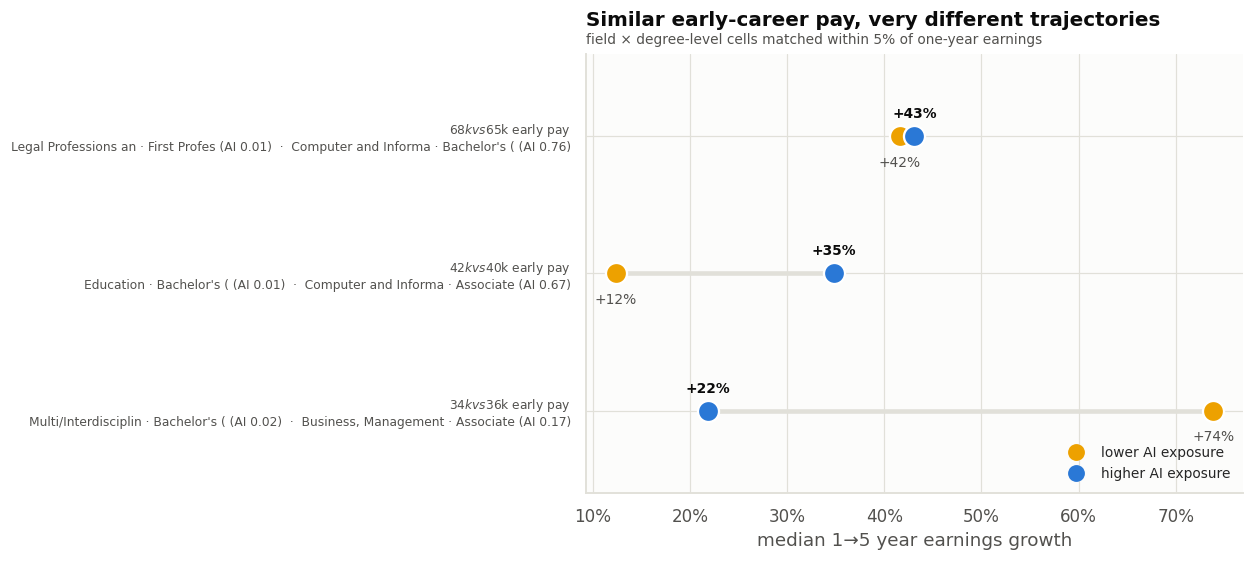

$  34,248 AI=0.02  +73.8%  |  $  35,802 AI=0.17  +21.8%   Multi/Interdisciplin · Bachelor's ( vs Business, Management · Associate
$  42,222 AI=0.01  +12.3%  |  $  40,282 AI=0.67  +34.8%   Education · Bachelor's ( vs Computer and Informa · Associate
$  67,853 AI=0.01  +41.6%  |  $  65,243 AI=0.76  +43.1%   Legal Professions an · First Profes vs Computer and Informa · Bachelor's (


In [ ]:
famcred = (ana.dropna(subset=["earnings_growth_pct_1yr_to_5yr", "ai_exposure_index"])
              .groupby(["cip_family_title", "degree_level_6"], observed=True)
              .agg(n=("program_id", "size"), pay=("median_earnings_1yr_usd", "median"),
                   ai=("ai_exposure_index", "median"),
                   growth=("earnings_growth_pct_1yr_to_5yr", "median"))
              .query("n >= 100").dropna())

# Use three pay terciles and a 5% pay caliper so "similar pay" is true at the cell level.
famcred["pay_tercile"] = pd.qcut(famcred["pay"], q=3, duplicates="drop")
pairs = []
for _, sub in famcred.groupby("pay_tercile", observed=True):
    sub = sub.reset_index()
    candidates = []
    for i in range(len(sub)):
        for j in range(i + 1, len(sub)):
            a, b = sub.iloc[i], sub.iloc[j]
            pay_mid = (a["pay"] + b["pay"]) / 2
            pay_gap_pct = 100 * abs(a["pay"] - b["pay"]) / pay_mid
            if pay_gap_pct <= 5:
                lo_r, hi_r = (a, b) if a["ai"] <= b["ai"] else (b, a)
                candidates.append((hi_r["ai"] - lo_r["ai"], -pay_gap_pct, lo_r, hi_r))
    if candidates:
        _, _, lo_r, hi_r = max(candidates, key=lambda x: (x[0], x[1]))
        pairs.append((lo_r, hi_r))

fig, ax = plt.subplots(figsize=(11.5, 5.2))
def cell_label(r):
    return f"{str(r['cip_family_title'])[:20]} · {str(r['degree_level_6'])[:12]}"

ylab = []
for i, (lo_r, hi_r) in enumerate(pairs):
    ax.plot([lo_r["growth"], hi_r["growth"]], [i, i], color=GRID, lw=3, zorder=1)
    ax.scatter(lo_r["growth"], i, s=190, color=CAT[3], zorder=3, edgecolors="white", linewidths=1.5)
    ax.scatter(hi_r["growth"], i, s=190, color=CAT[0], zorder=3, edgecolors="white", linewidths=1.5)
    ax.annotate(f"{lo_r['growth']:+.0f}%", (lo_r["growth"], i), xytext=(0, -20),
                textcoords="offset points", ha="center", fontsize=9, color=INK2)
    ax.annotate(f"{hi_r['growth']:+.0f}%", (hi_r["growth"], i), xytext=(0, 12),
                textcoords="offset points", ha="center", fontsize=9, color=INK, fontweight="bold")
    ylab.append(f"${lo_r['pay']/1000:,.0f}k vs ${hi_r['pay']/1000:,.0f}k early pay\n"
                f"{cell_label(lo_r)} (AI {lo_r['ai']:.2f})  ·  {cell_label(hi_r)} (AI {hi_r['ai']:.2f})")
ax.set_yticks(range(len(pairs))); ax.set_yticklabels(ylab, fontsize=8)
ax.xaxis.set_major_formatter(PCT); ax.set_ylim(-0.6, len(pairs)-0.4)
h = [plt.Line2D([0],[0], marker="o", ls="", ms=10, color=c, label=l)
     for c, l in [(CAT[3], "lower AI exposure"), (CAT[0], "higher AI exposure")]]
ax.legend(handles=h, loc="lower right", fontsize=9)
finish(ax, "Similar early-career pay, very different trajectories",
       "field × degree-level cells matched within 5% of one-year earnings",
       "median 1→5 year earnings growth", "")
plt.tight_layout(); plt.show()

for lo_r, hi_r in pairs:
    print(f"${lo_r['pay']:>8,.0f} AI={lo_r['ai']:.2f} {lo_r['growth']:+6.1f}%  |  "
          f"${hi_r['pay']:>8,.0f} AI={hi_r['ai']:.2f} {hi_r['growth']:+6.1f}%   "
          f"{cell_label(lo_r)} vs {cell_label(hi_r)}")

## 9.5 Conclusion — what the analysis can and cannot say

**AI exposure is a screening signal, not a causal growth forecast.**

- In the rerun table, emphasize the pay band with the largest positive `gap_pp`, while also
  reporting `pay_gap_pct` to show that the starting-pay groups were reasonably comparable.
- If the lowest-pay band moves in the opposite direction, treat it as an exception—not a
  universal "more AI is better" rule.
- Use high pay + high exposure to prioritize investment and curriculum review; use low exposure
  as a review flag, not a closure decision.

**Limits.** This is historical, cohort-level data. O*NET tool presence is a proxy for occupational
exposure; it does not measure displacement or prove that AI causes earnings growth.

> We are not producing a list of "programs AI will destroy." We are producing a screening map
> of where occupational AI exposure and earnings growth co-occur.

---
# 10 · Predictive modelling

## 10.1 Target, inputs, and the constraint that shapes everything

| Item | Detail |
|---|---|
| **Target** | `median_earnings_4yr_usd` — median earnings four years after completion |
| **Why year 4** | Best coverage; year 1 is too early (many are still studying or in a first job); it is the Department's headline metric |
| **Task** | Continuous → **regression**, not classification |
| **Split** | 40,000 sampled programs · 32,000 train / 8,000 test · `random_state = 42` |

**The constraint:** inputs are restricted to columns that are **never suppressed**. Nothing in
the feature set describes how graduates turned out. That is what lets the model score the
hidden programs in §12 — and it is why we cannot use debt, employment or the 1-year figure as
predictors, however useful they would be.

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor, plot_tree
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

TARGET = "median_earnings_4yr_usd"

BLOCK_NUM = {
 "Institution": ["institution_admission_rate","institution_avg_sat",
                 "institution_undergrad_enrollment","institution_tuition_in_state_usd",
                 "institution_tuition_out_state_usd"],
 "Program":     ["credential_level","awards_year1","awards_year2"],
 "Occupation":  ["occupation_employment_2024_thousands","occupation_growth_pct_2024_34",
                 "occupation_growth_pct_max","occupation_annual_openings_thousands",
                 "occupation_median_wage_2024_usd","linked_occupations_count",
                 "linked_occupations_in_bls","linked_occupations_in_onet"],
 "AI exposure": ["occupations_using_ai_software","ai_software_occupation_share",
                 "expert_system_occupation_share","ai_tools_max_per_occupation",
                 "hot_technologies_mean_per_occupation","ai_exposure_index"],
}
BLOCK_CAT = {
 "Institution": ["institution_control","institution_region"],
 "Program":     ["degree_level_6","distance_education","cip_family_title"],
 "Occupation":  ["occupation_typical_entry_education"],
 "AI exposure": [],
}
for b in BLOCK_NUM:
    BLOCK_NUM[b] = [c for c in BLOCK_NUM[b] if c in ana.columns]
    BLOCK_CAT[b] = [c for c in BLOCK_CAT[b] if c in ana.columns]

model_df = (ana.dropna(subset=[TARGET])
               .sample(min(40_000, ana[TARGET].notna().sum()), random_state=RANDOM_STATE))
y = model_df[TARGET]
idx_tr, idx_te = train_test_split(model_df.index, test_size=0.2, random_state=RANDOM_STATE)

def build_matrix(blocks, frame=None):
    frame = model_df if frame is None else frame
    num = sum([BLOCK_NUM[b] for b in blocks], [])
    cat = sum([BLOCK_CAT[b] for b in blocks], [])
    X = frame[num].copy()
    if cat:
        X = pd.concat([X, pd.get_dummies(frame[cat].astype(str), drop_first=True)], axis=1)
    return X

ALL_BLOCKS = list(BLOCK_NUM)
X_all = build_matrix(ALL_BLOCKS)
MED   = X_all.loc[idx_tr].median(numeric_only=True)
X_all = X_all.fillna(MED).fillna(0).astype(float)
X_train, X_test = X_all.loc[idx_tr], X_all.loc[idx_te]
y_train, y_test = y.loc[idx_tr], y.loc[idx_te]

print(f"Sampled {len(model_df):,} programs → {len(X_train):,} train / {len(X_test):,} test")
print(f"Feature matrix: {X_all.shape[1]} columns "
      f"({sum(len(v) for v in BLOCK_NUM.values())} numeric + one-hot expansions)")

Sampled 40,000 programs → 32,000 train / 8,000 test
Feature matrix: 84 columns (22 numeric + one-hot expansions)


## 10.2 Model 0 — the free option we have to beat

Before building anything, ask the uncomfortable question: *couldn't you just look up the
national median for that field and credential?* That column ships with the data. If our model
cannot beat it, the modelling is decoration.

In [ ]:
nb_pred = model_df.loc[idx_te, "national_median_earnings_4yr_usd"]
valid   = nb_pred.notna()
bench_r2  = r2_score(y_test[valid], nb_pred[valid])
bench_mae = mean_absolute_error(y_test[valid], nb_pred[valid])
bench_rmse = np.sqrt(mean_squared_error(y_test[valid], nb_pred[valid]))
print(f"MODEL 0 · national median for the same field+credential — no model at all")
print(f"  usable test rows {valid.sum():,}/{len(y_test):,}")
print(f"  R²   = {bench_r2:.3f}")
print(f"  RMSE = ${bench_rmse:,.0f}")
print(f"  MAE  = ${bench_mae:,.0f}      ← every model below must beat this")

MODEL 0 · national median for the same field+credential — no model at all
  usable test rows 8,000/8,000
  R²   = 0.696
  RMSE = $15,087
  MAE  = $9,528      ← every model below must beat this


## 10.3 The model ladder

In [ ]:
def score(name, y_true, y_pred):
    return {"Model": name, "R²": r2_score(y_true, y_pred),
            "RMSE ($)": np.sqrt(mean_squared_error(y_true, y_pred)),
            "MAE ($)": mean_absolute_error(y_true, y_pred)}

results, fitted = [], {}
results.append({"Model": "0 · National benchmark (no model)", "R²": bench_r2,
                "RMSE ($)": bench_rmse, "MAE ($)": bench_mae})

lin = LinearRegression().fit(X_train, y_train)
results.append(score("1 · Linear regression", y_test, lin.predict(X_test)))
fitted["1 · Linear regression"] = lin

lin_log = LinearRegression().fit(X_train, np.log(y_train))
results.append(score("2 · Linear regression (log target)", y_test, np.exp(lin_log.predict(X_test))))
fitted["2 · Linear regression (log target)"] = lin_log

tree = DecisionTreeRegressor(max_depth=4, min_samples_leaf=50,
                             random_state=RANDOM_STATE).fit(X_train, y_train)
results.append(score("3 · Decision tree (depth 4)", y_test, tree.predict(X_test)))
fitted["3 · Decision tree (depth 4)"] = tree

rf = RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                           random_state=RANDOM_STATE, n_jobs=-1).fit(X_train, y_train)
results.append(score("4 · Random forest (200 trees)", y_test, rf.predict(X_test)))
fitted["4 · Random forest (200 trees)"] = rf

res = pd.DataFrame(results).set_index("Model")
res["beats benchmark MAE by"] = (bench_mae - res["MAE ($)"]) / bench_mae * 100
print(res.round(3).to_string())

best = res.drop(index="0 · National benchmark (no model)")["R²"].idxmax()
print(f"\nBest model: {best}   R² = {res.loc[best,'R²']:.3f}   "
      f"MAE = ${res.loc[best,'MAE ($)']:,.0f}  "
      f"({(bench_mae-res.loc[best,'MAE ($)'])/bench_mae*100:.0f}% better than doing nothing)")

                                       R²   RMSE ($)    MAE ($)  beats benchmark MAE by
Model                                                                                  
0 · National benchmark (no model)   0.696  15086.987   9528.183                   0.000
1 · Linear regression               0.690  15214.994  10386.584                  -9.009
2 · Linear regression (log target)  0.704  14872.751   9883.669                  -3.731
3 · Decision tree (depth 4)         0.520  18933.826  13382.923                 -40.456
4 · Random forest (200 trees)       0.826  11417.959   7367.639                  22.675

Best model: 4 · Random forest (200 trees)   R² = 0.826   MAE = $7,368  (23% better than doing nothing)


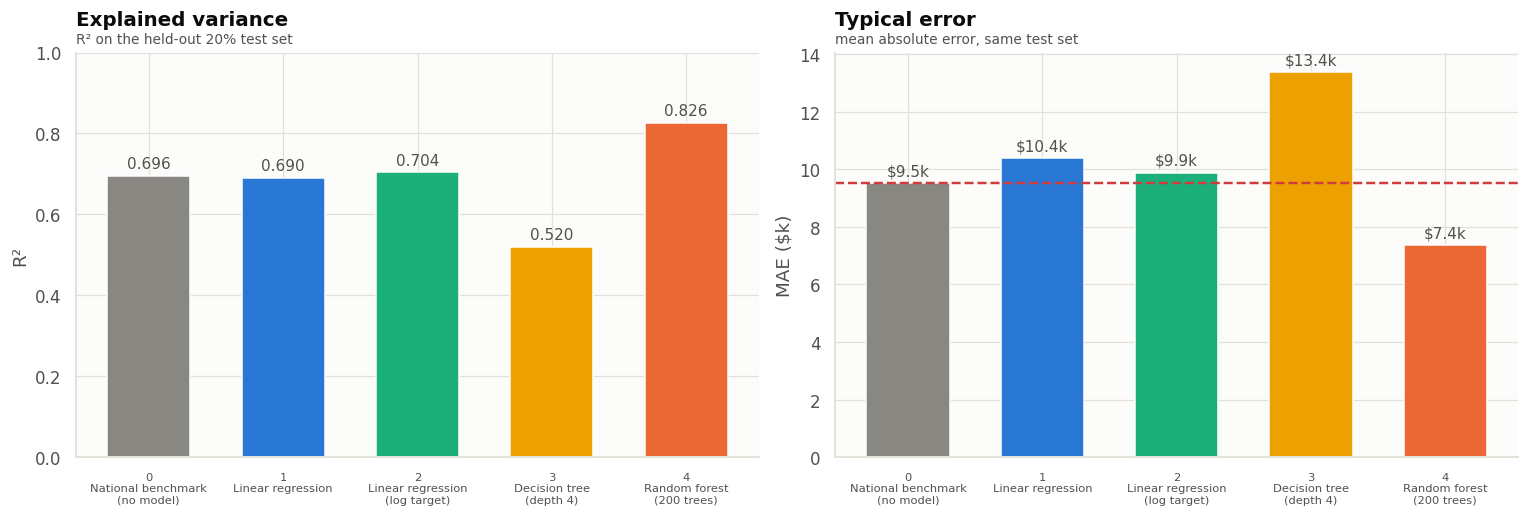

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
names = [n.replace(" (", "\n(").replace(" · ", "\n") for n in res.index]
cols  = [MUTED, CAT[0], CAT[2], CAT[3], CAT[1]]

axes[0].bar(names, res["R²"], color=cols, width=0.62)
for i, v in enumerate(res["R²"]):
    axes[0].annotate(f"{v:.3f}", (i, v), xytext=(0, 5), textcoords="offset points",
                     ha="center", color=INK2, fontsize=10)
axes[0].set_ylim(0, 1.0); axes[0].tick_params(axis="x", labelsize=7.5)
finish(axes[0], "Explained variance", "R² on the held-out 20% test set", "", "R²")

axes[1].bar(names, res["MAE ($)"]/1000, color=cols, width=0.62)
axes[1].axhline(bench_mae/1000, color="#d03b3b", ls="--", lw=1.6)
axes[1].annotate(f"  free option: ${bench_mae/1000:,.1f}k", (len(names)-0.4, bench_mae/1000),
                 xytext=(0, 6), textcoords="offset points", ha="right",
                 color="#d03b3b", fontsize=9, fontweight="bold")
for i, v in enumerate(res["MAE ($)"]):
    axes[1].annotate(f"${v/1000:,.1f}k", (i, v/1000), xytext=(0, 5),
                     textcoords="offset points", ha="center", color=INK2, fontsize=10)
axes[1].tick_params(axis="x", labelsize=7.5)
finish(axes[1], "Typical error", "mean absolute error, same test set", "", "MAE ($k)")
plt.tight_layout(); plt.show()

## 10.4 AI sensitivity — does AI exposure materially improve prediction?

We refit the same random forest on the same programs and test rows after removing the AI block. This is a predictive sensitivity check, not a causal test.


In [ ]:
NO_AI_BLOCKS = [b for b in ALL_BLOCKS if b != "AI exposure"]
X_no_ai = build_matrix(NO_AI_BLOCKS)
MED_NO_AI = X_no_ai.loc[idx_tr].median(numeric_only=True)
X_no_ai = X_no_ai.fillna(MED_NO_AI).fillna(0).astype(float)
X_no_ai_train, X_no_ai_test = X_no_ai.loc[idx_tr], X_no_ai.loc[idx_te]

rf_no_ai = RandomForestRegressor(n_estimators=200, min_samples_leaf=2,
                                 random_state=RANDOM_STATE, n_jobs=-1).fit(
                                     X_no_ai_train, y_train)
pred_no_ai = rf_no_ai.predict(X_no_ai_test)
ai_sensitivity = pd.DataFrame([
    score("AI variables included", y_test, rf.predict(X_test)),
    score("AI variables removed", y_test, pred_no_ai),
]).set_index("Model")
print("Sensitivity result — predictive value, not causality:")
print(ai_sensitivity.round(3).to_string())
print(f"R² change after removing AI variables: "
      f"{ai_sensitivity.loc['AI variables included', 'R²']:.3f} → "
      f"{ai_sensitivity.loc['AI variables removed', 'R²']:.3f}")


Sensitivity result — predictive value, not causality:
                          R²   RMSE ($)   MAE ($)
Model                                            
AI variables included  0.826  11417.959  7367.639
AI variables removed   0.821  11569.262  7468.485
R² change after removing AI variables: 0.826 → 0.821


**Read this chart.** The log-target rung beats the raw one, exactly as the skew in §8.1
predicted — a small but satisfying case of EDA paying off downstream. The depth-4 tree is the
weakest by design (we cap it so it stays readable). The forest is the accuracy rung.

**So what.** Note the red line. Two of our four models are *worse than doing nothing*. Only the
forest clears the free option by a meaningful margin — which is the honest way to report a
model, and it sets up the next section.

## 10.5 Ablation — which data source actually earned its place?

We built the feature set from four blocks. Adding them one at a time answers the question a
sceptical grader will ask: **was the three-source join worth the effort?**

Note this cuts *columns*, not rows — all 32,000 training programs are used throughout.

In [ ]:
SEQ_BLOCKS = [["Institution"],
              ["Institution","Program"],
              ["Institution","Program","Occupation"],
              ["Institution","Program","Occupation","AI exposure"]]

def run_blocks(blocks, n_estimators=200):
    X = build_matrix(blocks)
    X = X.fillna(X.loc[idx_tr].median(numeric_only=True)).fillna(0).astype(float)
    Xtr, Xte = X.loc[idx_tr], X.loc[idx_te]
    m = RandomForestRegressor(n_estimators=n_estimators, min_samples_leaf=2,
                              random_state=RANDOM_STATE, n_jobs=-1).fit(Xtr, y_train)
    p = m.predict(Xte)
    return {"columns": X.shape[1], "R²": r2_score(y_test, p),
            "MAE ($)": mean_absolute_error(y_test, p)}

abl = [{"inputs": "0 · No model (national benchmark)", "columns": np.nan,
        "R²": bench_r2, "MAE ($)": bench_mae}]
for blocks in SEQ_BLOCKS:
    r = run_blocks(blocks); r["inputs"] = " + ".join(blocks); abl.append(r)
abl = pd.DataFrame(abl)[["inputs","columns","R²","MAE ($)"]]
abl["Δ R² vs previous"] = abl["R²"].diff()
print(abl.round(3).to_string(index=False))

                                          inputs  columns    R²   MAE ($)  Δ R² vs previous
               0 · No model (national benchmark)      NaN 0.696  9528.183               NaN
                                     Institution     17.0 0.313 16627.520            -0.382
                           Institution + Program     64.0 0.706  9746.345             0.393
              Institution + Program + Occupation     78.0 0.821  7468.485             0.115
Institution + Program + Occupation + AI exposure     84.0 0.826  7367.639             0.005


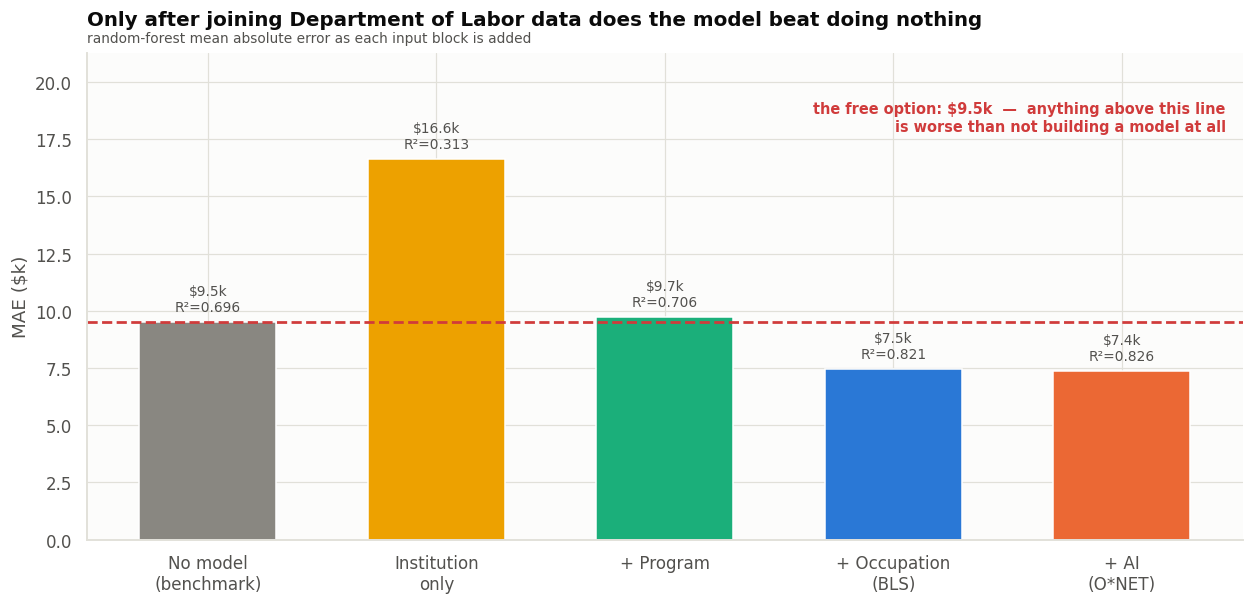

Reverse check — drop one block at a time from the full model:
  without Institution   R² 0.826 → 0.704  (-0.122)   MAE $9,868
  without Program       R² 0.826 → 0.691  (-0.134)   MAE $10,105
  without Occupation    R² 0.826 → 0.812  (-0.014)   MAE $7,618
  without AI exposure   R² 0.826 → 0.821  (-0.005)   MAE $7,477


In [ ]:
fig, ax = plt.subplots(figsize=(11.5, 5.6))
lab = ["No model\n(benchmark)", "Institution\nonly", "+ Program", "+ Occupation\n(BLS)", "+ AI\n(O*NET)"]
bar_cols = [MUTED, CAT[3], CAT[2], CAT[0], CAT[1]]
ax.bar(lab, abl["MAE ($)"]/1000, color=bar_cols, width=0.6)
ax.axhline(bench_mae/1000, color="#d03b3b", ls="--", lw=1.8)
ax.annotate(f"the free option: ${bench_mae/1000:,.1f}k  —  anything above this line\n"
            f"is worse than not building a model at all",
            xy=(0.985, 0.90), xycoords="axes fraction", ha="right", va="top",
            color="#d03b3b", fontsize=9.5, fontweight="bold")
for i, (v, r2) in enumerate(zip(abl["MAE ($)"], abl["R²"])):
    ax.annotate(f"${v/1000:,.1f}k\nR²={r2:.3f}", (i, v/1000), xytext=(0, 7),
                textcoords="offset points", ha="center", color=INK2, fontsize=9)
ax.set_ylim(0, abl["MAE ($)"].max()/1000*1.28)
finish(ax, "Only after joining Department of Labor data does the model beat doing nothing",
       "random-forest mean absolute error as each input block is added",
       "", "MAE ($k)")
plt.tight_layout(); plt.show()

print("Reverse check — drop one block at a time from the full model:")
full = run_blocks(ALL_BLOCKS, n_estimators=120)
for b in ALL_BLOCKS:
    r = run_blocks([x for x in ALL_BLOCKS if x != b], n_estimators=120)
    print(f"  without {b:12s}  R² {full['R²']:.3f} → {r['R²']:.3f}  "
          f"({r['R²']-full['R²']:+.3f})   MAE ${r['MAE ($)']:,.0f}")

**Read this chart — this is the single most important table in the project.**

1. Knowing only **which institution** a student attends barely predicts anything.
2. Adding **what you study** is the largest single jump.
3. **The critical line:** with institution + program the model is *still worse than the free
   option*. We would have shipped a model that adds nothing.
4. Only after adding **BLS occupation data** does it clear the benchmark.

**So what.** The value of this project is not "we built a model." It is **"we joined Department
of Education outcomes to Department of Labor projections."** Without that join, the modelling is
decoration.

On the reverse check: Occupation adds a lot when *introduced* but costs little when *removed* —
because the information is redundant with field of study (knowing a program is "Nursing" already
implies the occupation). That is not a contradiction; the two experiments answer different
questions — *how much does it add* versus *how irreplaceable is it*.

## 10.6 What linear regression tells us — and where it breaks

The forest is more accurate, but it cannot answer "what is a master's worth?" in dollars. Linear
regression can, so we keep it for interpretation.

Near-duplicate input pairs (|r| > 0.9):
linked_occupations_in_bls             linked_occupations_in_onet              0.997
linked_occupations_count              linked_occupations_in_bls               0.996
                                      linked_occupations_in_onet              0.996
occupation_employment_2024_thousands  occupation_annual_openings_thousands    0.994
awards_year1                          awards_year2                            0.971
occupation_annual_openings_thousands  linked_occupations_in_onet              0.880

When two inputs are ~0.99 correlated the model can put a huge positive weight on one
and a huge negative weight on the other. Prediction is unaffected; interpretation is ruined.
So for the coefficient story we refit on a decorrelated subset — one of each pair.

Interpretation model: R² = 0.682 (full model 0.690) — dropping the duplicates costs almost no accuracy

Ranked by how much each factor can actually move the prediction
(coefficient × that varia

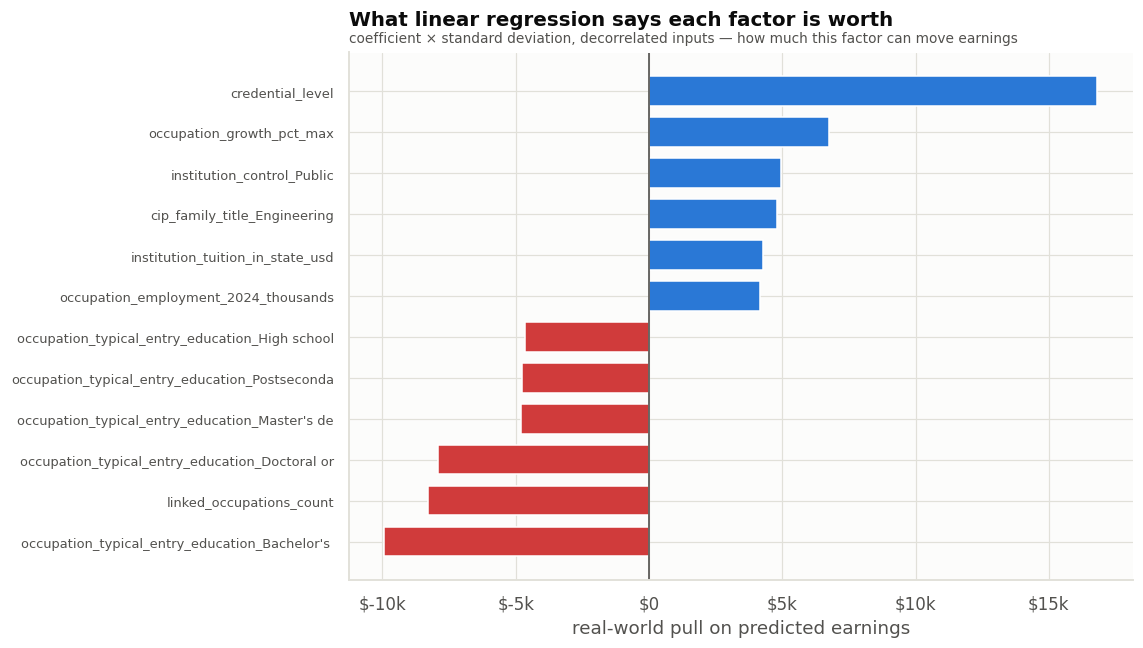

In [ ]:
# Coefficients are only interpretable if the inputs are not near-duplicates of each other.
# Several of ours are: check before reading anything off the model.
COLL = ["occupation_employment_2024_thousands","occupation_annual_openings_thousands",
        "linked_occupations_count","linked_occupations_in_bls","linked_occupations_in_onet",
        "institution_tuition_in_state_usd","institution_tuition_out_state_usd",
        "awards_year1","awards_year2","occupation_growth_pct_2024_34","occupation_growth_pct_max"]
COLL = [c for c in COLL if c in ana.columns]
cm = ana[COLL].corr().abs()
pairs = (cm.where(np.triu(np.ones(cm.shape), 1).astype(bool)).stack()
           .sort_values(ascending=False).head(6))
print("Near-duplicate input pairs (|r| > 0.9):")
print(pairs.round(3).to_string())
print("\nWhen two inputs are ~0.99 correlated the model can put a huge positive weight on one")
print("and a huge negative weight on the other. Prediction is unaffected; interpretation is ruined.")
print("So for the coefficient story we refit on a decorrelated subset — one of each pair.\n")

# ── decorrelated interpretation model ───────────────────────────────────────
DROP = ["occupation_annual_openings_thousands", "linked_occupations_in_bls",
        "linked_occupations_in_onet", "institution_tuition_out_state_usd", "awards_year1"]
interp_cols = [c for c in X_train.columns if c not in DROP]
lin_interp = LinearRegression().fit(X_train[interp_cols], y_train)
p_interp = lin_interp.predict(X_test[interp_cols])
print(f"Interpretation model: R² = {r2_score(y_test, p_interp):.3f} "
      f"(full model {res.loc['1 · Linear regression','R²']:.3f}) — "
      f"dropping the duplicates costs almost no accuracy")

coef = pd.Series(lin_interp.coef_, index=interp_cols)
pull = (coef * X_train[interp_cols].std()).rename("real_pull")
top  = pull.abs().sort_values(ascending=False).head(12).index
print("\nRanked by how much each factor can actually move the prediction")
print("(coefficient × that variable's spread in the training data)\n")
print(pd.DataFrame({"coefficient": coef[top].round(2),
                    "real pull ($)": pull[top].round(0)}).to_string())

fig, ax = plt.subplots(figsize=(10.5, 6))
srt = pull[top].sort_values()
ax.barh([t[:46] for t in srt.index], srt.values,
        color=["#d03b3b" if v < 0 else CAT[0] for v in srt.values], height=0.72)
ax.axvline(0, color=INK2, lw=1.1)
ax.xaxis.set_major_formatter(USD); ax.tick_params(axis="y", labelsize=8.5)
finish(ax, "What linear regression says each factor is worth",
       "coefficient × standard deviation, decorrelated inputs — how much this factor can move earnings",
       "real-world pull on predicted earnings", "")
plt.tight_layout(); plt.show()

In [ ]:
# A worked example: feed the model a Computer Science master's and see what it says.
cs_mask = (model_df["cip_family_title"].str.startswith("Computer")
           & model_df["degree_level_6"].eq("Master's"))
if cs_mask.sum() > 0:
    ex_X   = X_all.loc[model_df.index[cs_mask]].median().to_frame().T
    ex_pred = lin.predict(ex_X)[0]
    ex_act  = model_df.loc[cs_mask, TARGET].median()
    print("Worked example — a typical Computer Science master's programme")
    print(f"  linear regression predicts : ${ex_pred:,.0f}")
    print(f"  actual median              : ${ex_act:,.0f}")
    print(f"  error                      : ${ex_act-ex_pred:,.0f}")
    print("\n  It cannot say 'if it is Computer Science, that credential level is worth more'.")
    print("  Additive structure forces one number for 'the value of a master's' everywhere.")

Worked example — a typical Computer Science master's programme
  linear regression predicts : $107,376
  actual median              : $125,170
  error                      : $17,795

  It cannot say 'if it is Computer Science, that credential level is worth more'.
  Additive structure forces one number for 'the value of a master's' everywhere.


**Read this.** Credential level and the destination occupation's wage dominate. Engineering
carries a large positive coefficient and Visual & Performing Arts a large negative one — a swing
of tens of thousands of dollars at the same school, same credential. Institutional SAT is worth
comparatively little.

**So what — and a methodological catch worth naming.** Our first attempt at this chart put
*occupation employment size* on top with a huge positive weight and *annual openings* at the
bottom with a huge negative one. Those two variables correlate at r = 0.99. When inputs are
near-duplicates, a linear model can hand one a large positive coefficient and the other a large
negative one that cancels it; the predictions are fine but the coefficients are meaningless.
**Collinearity does not hurt accuracy — it destroys interpretability.** Since the whole reason we
keep linear regression is interpretation, we refit on a decorrelated subset before reading
anything off it.

## 10.7 Grouped regression — doing "it depends" by hand

Same inputs, same linear model, fitted **separately** for three field groups. This keeps the
interpretability of coefficients while letting the value of a credential vary.

In [ ]:
STEM = {"Biological and Biomedical Sciences","Computer and Information Sciences and Support Services",
 "Engineering","Engineering/Engineering-Related Technologies/Technicians","Mathematics and Statistics",
 "Physical Sciences","Science Technologies/Technicians",
 "Agricultural/Animal/Plant/Veterinary Science and Related Fields",
 "Natural Resources and Conservation","Architecture and Related Services"}
HUM = {"Area, Ethnic, Cultural, Gender, and Group Studies","Communication, Journalism, and Related Programs",
 "English Language and Literature/Letters","Foreign Languages, Literatures, and Linguistics","History",
 "Liberal Arts and Sciences, General Studies and Humanities","Philosophy and Religious Studies",
 "Psychology","Social Sciences","Theology and Religious Vocations","Visual and Performing Arts",
 "Library Science","Multi/Interdisciplinary Studies","Education",
 "Public Administration and Social Service Professions"}
def field_group(f):
    return "STEM" if f in STEM else ("Humanities & social sciences" if f in HUM
                                     else "Business / health / trades")

SIMPLE = ["credential_level","occupation_median_wage_2024_usd","occupation_growth_pct_2024_34",
          "institution_tuition_in_state_usd","institution_avg_sat","awards_year2","ai_exposure_index"]
SIMPLE = [c for c in SIMPLE if c in ana.columns]
gdf = ana.dropna(subset=[TARGET]).assign(group=lambda t: t["cip_family_title"].map(field_group))

def fit_group(frame, label):
    X = frame[SIMPLE].copy(); X = X.fillna(X.median(numeric_only=True))
    yy = frame[TARGET]
    Xtr, Xte, ytr, yte = train_test_split(X, yy, test_size=.2, random_state=RANDOM_STATE)
    m = LinearRegression().fit(Xtr, ytr); p = m.predict(Xte)
    return {"group": label, "n": len(frame), "median earnings": yy.median(),
            "R²": r2_score(yte, p), "MAE ($)": mean_absolute_error(yte, p),
            "value of 1 credential level": dict(zip(SIMPLE, m.coef_))["credential_level"],
            "occupation-wage coef": dict(zip(SIMPLE, m.coef_))["occupation_median_wage_2024_usd"]}

rows = [fit_group(gdf, "All pooled together")]
for g in ["STEM", "Humanities & social sciences", "Business / health / trades"]:
    rows.append(fit_group(gdf[gdf["group"].eq(g)], g))
grp = pd.DataFrame(rows).set_index("group")
wm = np.average(grp.iloc[1:]["MAE ($)"], weights=grp.iloc[1:]["n"])
print(grp.round(3).to_string())
print(f"\nPooled MAE ${grp.loc['All pooled together','MAE ($)']:,.0f} → "
      f"weighted MAE after splitting ${wm:,.0f}  "
      f"({(grp.loc['All pooled together','MAE ($)']-wm)/grp.loc['All pooled together','MAE ($)']*100:.0f}% better)")

                                  n  median earnings     R²    MAE ($)  value of 1 credential level  occupation-wage coef
group                                                                                                                    
All pooled together           50229          59054.0  0.458  14629.351                     8830.574                 0.174
STEM                           8952          75884.0  0.506  15791.647                    12340.671                 0.239
Humanities & social sciences  16967          53287.0  0.483   8708.111                     8146.257                 0.085
Business / health / trades    24310          60506.5  0.527  14719.353                     9185.001                 0.287

Pooled MAE $14,629 → weighted MAE after splitting $12,880  (12% better)


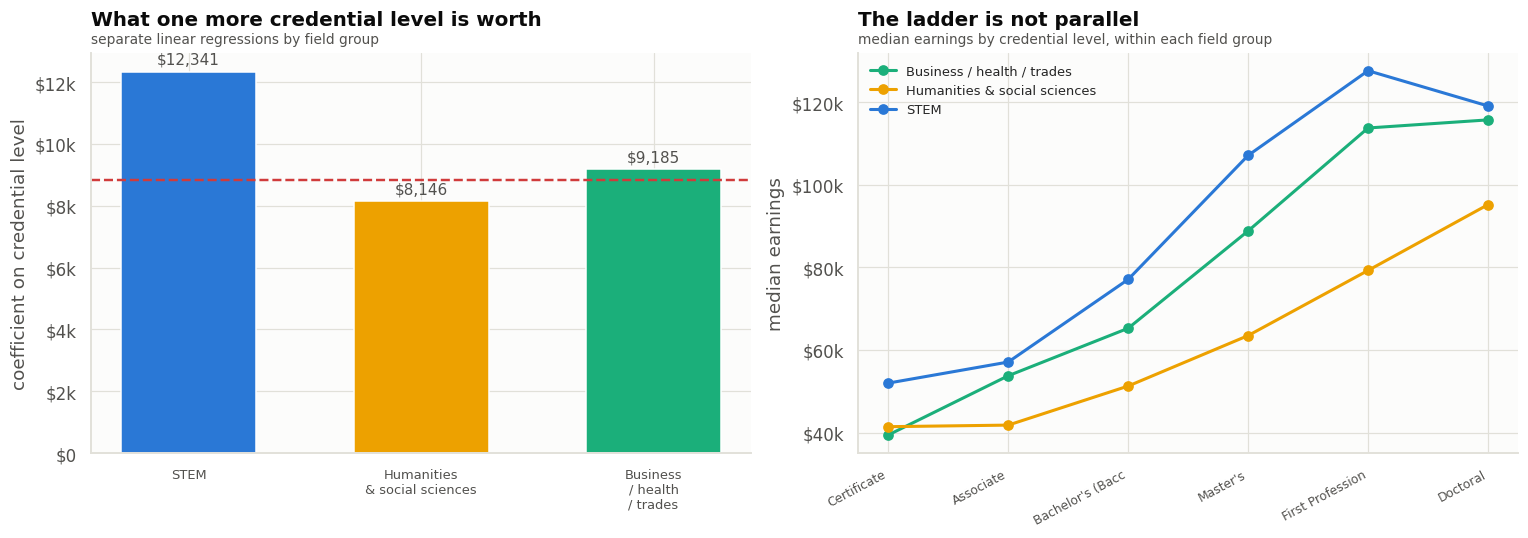

Bachelor's -> Master's, median jump:
  Business / health / trades       $  65,250 -> $  88,820   (+$23,570)
  Humanities & social sciences     $  51,256 -> $  63,480   (+$12,224)
  STEM                             $  77,082 -> $ 107,108   (+$30,027)


In [ ]:
ladder = (gdf.pivot_table(index="degree_level_6", columns="group",
                          values=TARGET, aggfunc="median", observed=True)
             .reindex([c for c in cred_order if c in gdf["degree_level_6"].unique()]))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sub = grp.iloc[1:]
axes[0].bar(range(len(sub)), sub["value of 1 credential level"],
            color=[CAT[0], CAT[3], CAT[2]], width=0.58)
axes[0].axhline(grp.loc["All pooled together","value of 1 credential level"],
                color="#d03b3b", ls="--", lw=1.6)
axes[0].annotate(f"pooled model says one number for everyone: "
                 f"${grp.loc['All pooled together','value of 1 credential level']:,.0f}",
                 (len(sub)-0.5, grp.loc["All pooled together","value of 1 credential level"]),
                 xytext=(0, 8), textcoords="offset points", ha="right",
                 color="#d03b3b", fontsize=9, fontweight="bold")
for i, v in enumerate(sub["value of 1 credential level"]):
    axes[0].annotate(f"${v:,.0f}", (i, v), xytext=(0, 5), textcoords="offset points",
                     ha="center", color=INK2, fontsize=10)
axes[0].set_xticks(range(len(sub)))
axes[0].set_xticklabels([s.replace(" & ", "\n& ").replace(" / ", "\n/ ") for s in sub.index], fontsize=8.5)
axes[0].yaxis.set_major_formatter(USD)
finish(axes[0], "What one more credential level is worth",
       "separate linear regressions by field group", "", "coefficient on credential level")

for j, g in enumerate(ladder.columns):
    axes[1].plot(range(len(ladder)), ladder[g], marker="o", lw=2,
                 color=[CAT[2], CAT[3], CAT[0]][j], label=g)
axes[1].set_xticks(range(len(ladder)))
axes[1].set_xticklabels([c[:16] for c in ladder.index], rotation=28, ha="right", fontsize=8)
axes[1].yaxis.set_major_formatter(USD); axes[1].legend(fontsize=8.5)
finish(axes[1], "The ladder is not parallel",
       "median earnings by credential level, within each field group", "", "median earnings")
plt.tight_layout(); plt.show()

BA, MA = "Bachelor's (Baccalaureate)", "Master's"
if BA in ladder.index and MA in ladder.index:
    print("Bachelor's -> Master's, median jump:")
    for g in ladder.columns:
        lo_v, hi_v = ladder.loc[BA, g], ladder.loc[MA, g]
        print(f"  {g:32s} ${lo_v:>8,.0f} -> ${hi_v:>8,.0f}   (+${hi_v-lo_v:,.0f})")

**Read these charts.** Splitting the regression cuts error by roughly a tenth — but the real
gain is seeing what the pooled model averaged away. The credential ladder is steeper in STEM
than in humanities, so "the value of a master's" is not one number.

**So what.** A side finding worth noting: the coefficient on occupation wage is much weaker in
humanities than in STEM. Humanities graduates' earnings have comparatively little to do with
their nominally linked occupation — because many do not enter it. **Practical implication:**
occupational projections are a sound basis for advising STEM students and a poor one for
advising humanities students.

## 10.8 The decision tree — a diagnostic order, not a set of weights

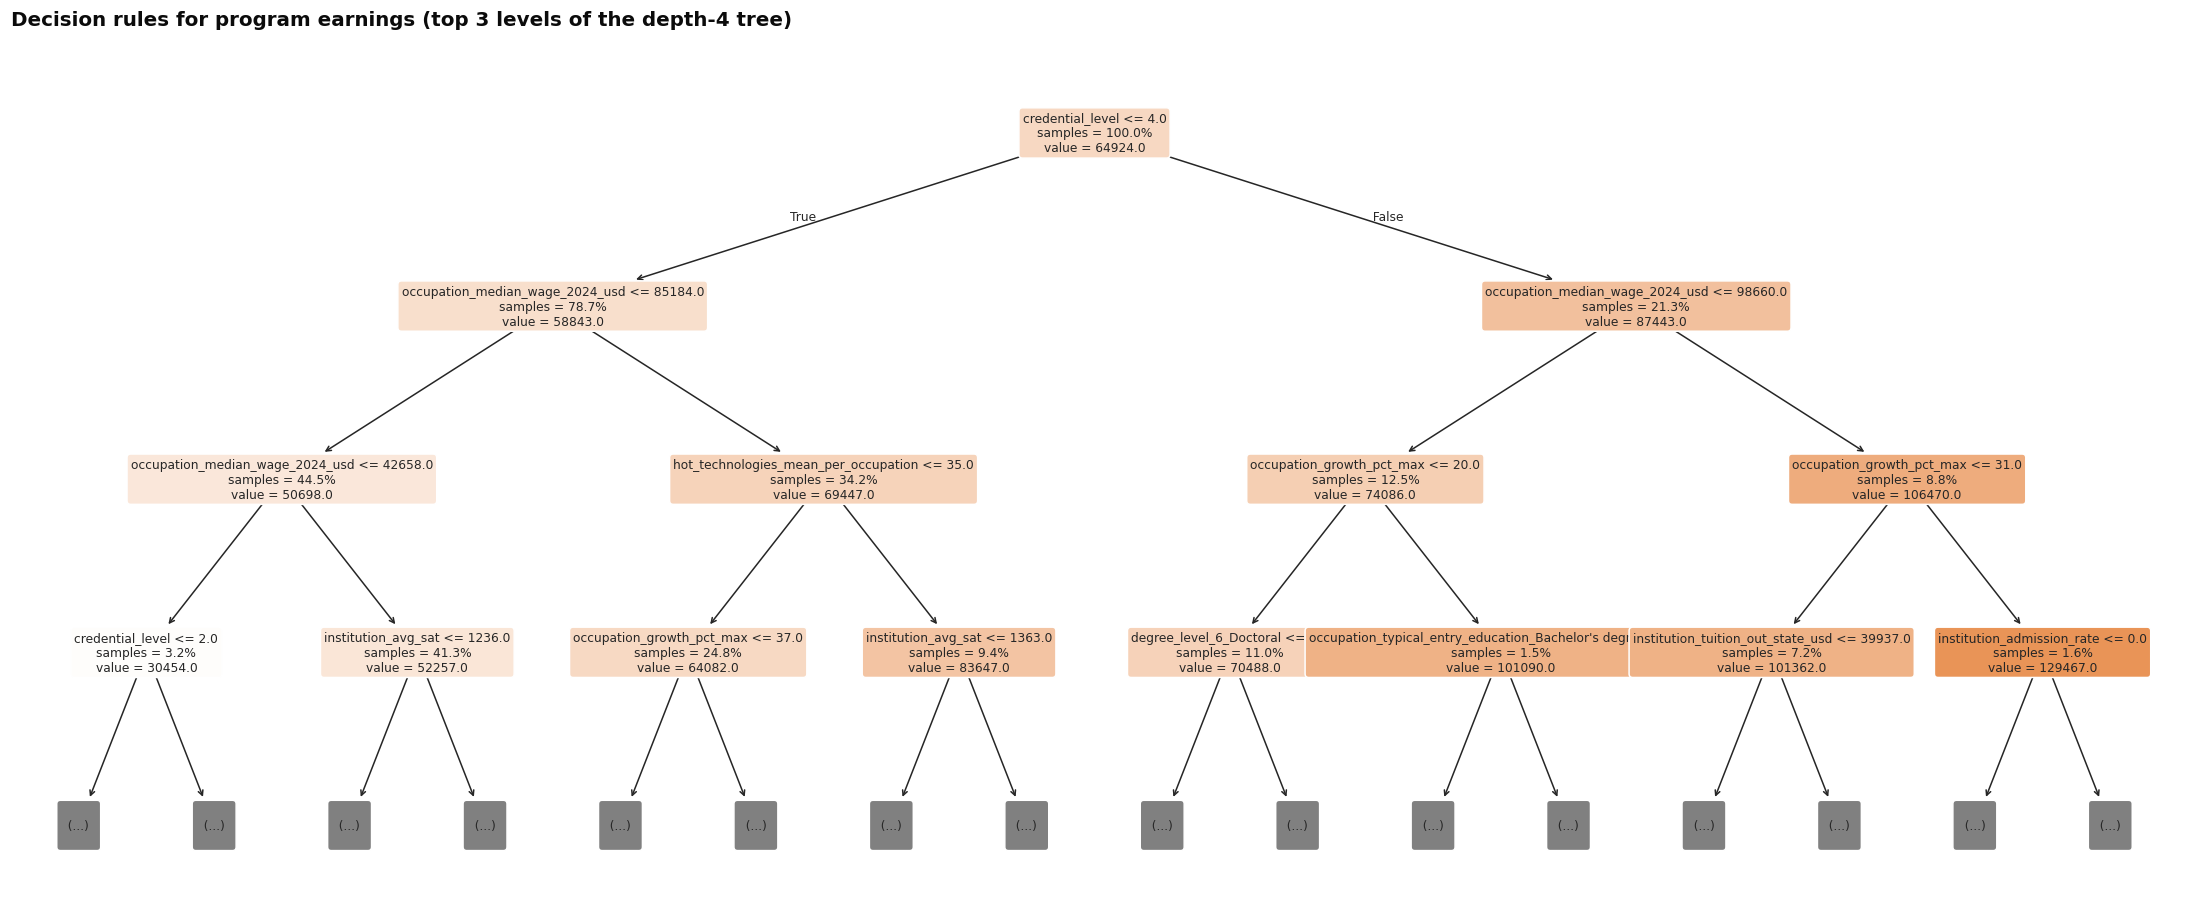

Variables the tree actually splits on:
credential_level                                        0.364
occupation_median_wage_2024_usd                         0.359
occupation_growth_pct_max                               0.106
hot_technologies_mean_per_occupation                    0.069
institution_avg_sat                                     0.050
institution_tuition_out_state_usd                       0.022
degree_level_6_Doctoral                                 0.017
occupation_typical_entry_education_Bachelor's degree    0.010
institution_admission_rate                              0.003


In [ ]:
fig, ax = plt.subplots(figsize=(20, 8.5))
plot_tree(tree, feature_names=list(X_train.columns), filled=True, rounded=True,
          fontsize=8, max_depth=3, impurity=False, precision=0, ax=ax, proportion=True)
ax.set_title("Decision rules for program earnings (top 3 levels of the depth-4 tree)",
             loc="left", fontsize=13, color=INK, pad=14)
plt.tight_layout(); plt.show()

splits = pd.Series(tree.feature_importances_, index=X_train.columns)
print("Variables the tree actually splits on:")
print(splits[splits > 0].sort_values(ascending=False).round(3).to_string())

**Read this tree.** The first question is always **credential level**. The second is always the
**destination occupation's wage** — but the threshold *moves* between the two branches: an
occupation has to pay more before it counts as "high-paying" for a graduate programme. Field of
study only appears at the third level, and only on one branch.

**So what.** This is a rule set a review committee can use without any statistics, and it is
exactly the "it depends" structure linear regression cannot express — the tree found it without
being told to look.

## 10.9 Feature importance — the bridge from model to recommendation

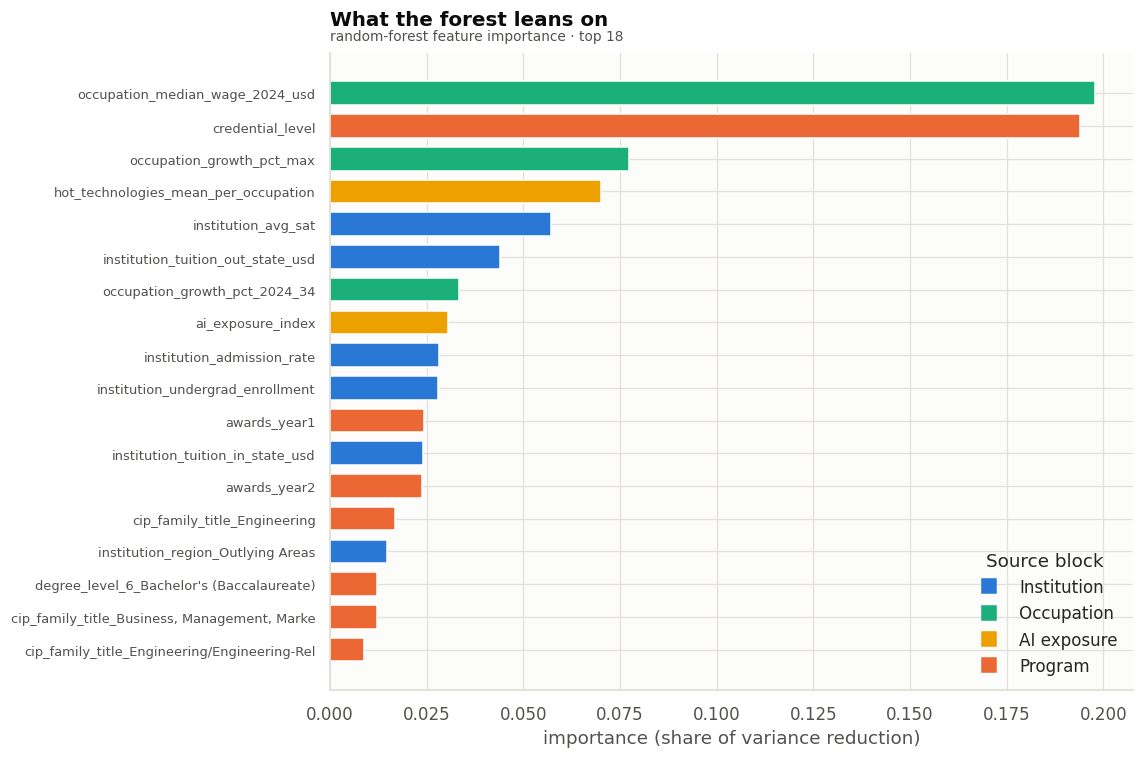

Importance by source block:
Occupation     33.8
Program        33.0
Institution    21.6
AI exposure    11.6

Program + Occupation = 66.8% vs Institution 21.6%


In [ ]:
imp = (pd.Series(rf.feature_importances_, index=X_train.columns)
         .sort_values(ascending=False).head(18)[::-1])

def block_of_feature(f):
    for b in ALL_BLOCKS:
        if f in BLOCK_NUM[b]: return b
        if any(f.startswith(c + "_") for c in BLOCK_CAT[b]): return b
    return "Program"

BLOCK_COLOR = {"Institution": CAT[0], "Occupation": CAT[2],
               "AI exposure": CAT[3], "Program": CAT[1]}
cols = [BLOCK_COLOR[block_of_feature(f)] for f in imp.index]

fig, ax = plt.subplots(figsize=(10.5, 7))
ax.barh(range(len(imp)), imp.values, color=cols, height=0.72)
ax.set_yticks(range(len(imp))); ax.set_yticklabels([f[:44] for f in imp.index], fontsize=8.5)
handles = [plt.Line2D([0],[0], marker="s", ls="", ms=9, color=c, label=b)
           for b, c in BLOCK_COLOR.items()]
ax.legend(handles=handles, loc="lower right")
finish(ax, "What the forest leans on", "random-forest feature importance · top 18",
       "importance (share of variance reduction)", "", legend_title="Source block")
plt.tight_layout(); plt.show()

by_block = (pd.Series(rf.feature_importances_, index=X_train.columns)
              .groupby(block_of_feature).sum().sort_values(ascending=False) * 100)
print("Importance by source block:")
print(by_block.round(1).to_string())
print(f"\nProgram + Occupation = {by_block.get('Program',0)+by_block.get('Occupation',0):.1f}% "
      f"vs Institution {by_block.get('Institution',0):.1f}%")

**Read this chart.** Credential level and the destination occupation's wage sit at the top —
the same two variables the tree split on first, and the same two the regression ranked highest.
Three methods, one answer.

**So what.** Grouped by source: **what you study and where it leads accounts for roughly
two-thirds of the model, against under a quarter for where you study.** That single sentence is
the most useful thing this analysis has to say to academic leadership.

## 10.10 Error analysis — where the model is wrong, and why

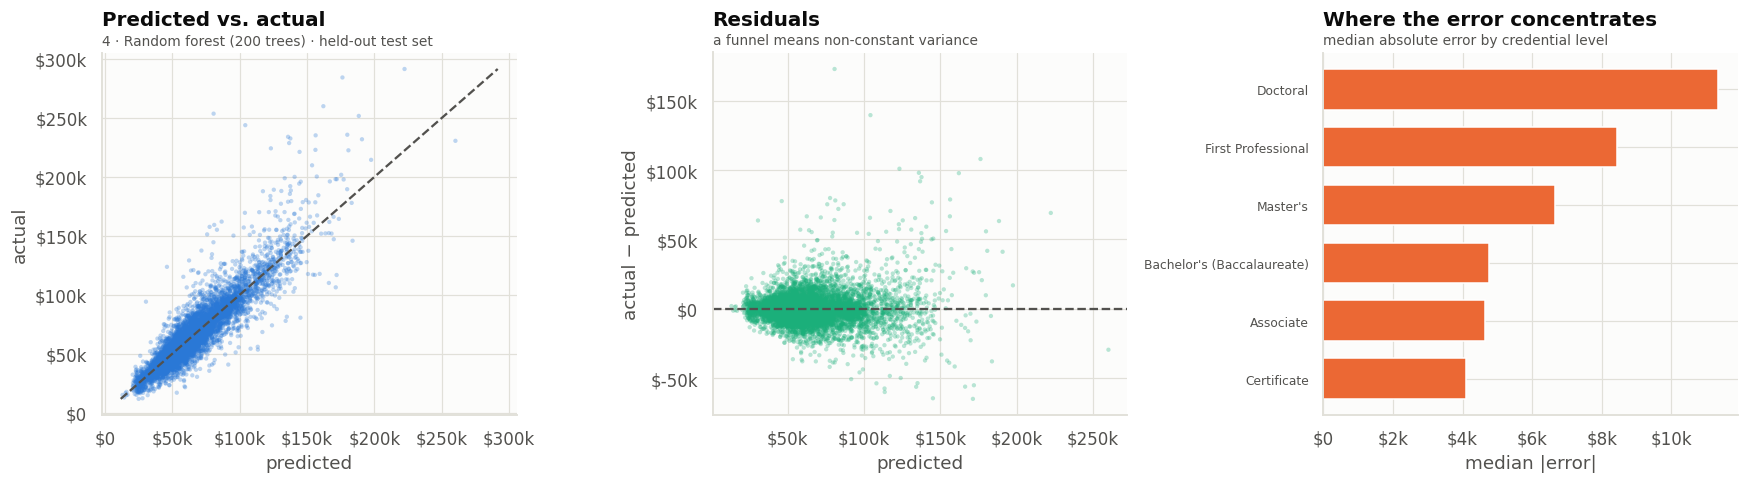

Median |error|: $4,991
Within ±$10k: 76.8% of test programs


In [ ]:
pred = fitted[best].predict(X_test)
if "log target" in best:
    pred = np.exp(pred)
resid = y_test - pred

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
axes[0].scatter(pred, y_test, s=8, alpha=0.3, color=CAT[0], edgecolors="none")
lim = [min(pred.min(), y_test.min()), max(pred.max(), y_test.max())]
axes[0].plot(lim, lim, color=INK2, ls="--", lw=1.5)
axes[0].xaxis.set_major_formatter(USD); axes[0].yaxis.set_major_formatter(USD)
finish(axes[0], "Predicted vs. actual", f"{best} · held-out test set", "predicted", "actual")

axes[1].scatter(pred, resid, s=8, alpha=0.3, color=CAT[2], edgecolors="none")
axes[1].axhline(0, color=INK2, ls="--", lw=1.5)
axes[1].xaxis.set_major_formatter(USD); axes[1].yaxis.set_major_formatter(USD)
finish(axes[1], "Residuals", "a funnel means non-constant variance", "predicted", "actual − predicted")

err = (pd.DataFrame({"resid": np.abs(resid),
                     "cred": model_df.loc[y_test.index, "degree_level_6"].astype(str)})
       .groupby("cred")["resid"].median().sort_values().tail(9))
axes[2].barh([c[:30] for c in err.index], err.values, color=CAT[1], height=0.7)
axes[2].xaxis.set_major_formatter(USD); axes[2].tick_params(axis="y", labelsize=8)
finish(axes[2], "Where the error concentrates", "median absolute error by credential level",
       "median |error|", "")
plt.tight_layout(); plt.show()

print(f"Median |error|: ${np.abs(resid).median():,.0f}")
print(f"Within ±$10k: {(np.abs(resid) <= 10_000).mean()*100:.1f}% of test programs")

**Read these charts.** Predictions track the diagonal through the bulk of the range but
compress at the top — the forest under-predicts the highest-paying programs, because averaging
200 trees pulls extremes toward the middle. The residual funnel confirms variance grows with
predicted earnings.

**So what.** The brief asks us to explain poor performance rather than hide it. Two honest
consequences: (1) we quote a **typical error band**, not a point estimate; (2) error concentrates
in small, heterogeneous credential types with few training examples — which is precisely where
§12 tells the reader to trust the estimates least.

---
# 11 · Lighting up the hidden two-thirds

Everything so far used the visible third of the catalogue. This section is the payoff: because
every input is drawn from never-suppressed columns, the model can score programs the Department
of Education will not report.

In [ ]:
hid = hidden.copy()
X_hidden = build_matrix(ALL_BLOCKS, frame=hid).reindex(columns=X_train.columns)
dummy_cols = [c for c in X_train.columns
              if c not in sum(BLOCK_NUM.values(), []) ]
X_hidden[dummy_cols] = X_hidden[dummy_cols].fillna(0)
X_hidden = X_hidden.fillna(MED).fillna(0).astype(float)

p_hidden = fitted[best].predict(X_hidden)
if "log target" in best:
    p_hidden = np.exp(p_hidden)
hid["predicted_earnings"] = p_hidden
rmse_best = res.loc[best, "RMSE ($)"]

print(f"Scored {len(hid):,} previously invisible programs using {best}")
print(f"  estimated median  ${np.median(p_hidden):,.0f}")
print(f"  interquartile     ${np.percentile(p_hidden,25):,.0f} – ${np.percentile(p_hidden,75):,.0f}")
print(f"  typical error     ±${rmse_best:,.0f}")
print(f"\nCatalogue coverage: {len(ana):,} reported + {len(hid):,} estimated = {len(d):,} (100%)")

Scored 100,336 previously invisible programs using 4 · Random forest (200 trees)
  estimated median  $57,684
  interquartile     $47,434 – $74,700
  typical error     ±$11,418

Catalogue coverage: 50,229 reported + 100,336 estimated = 150,565 (100%)


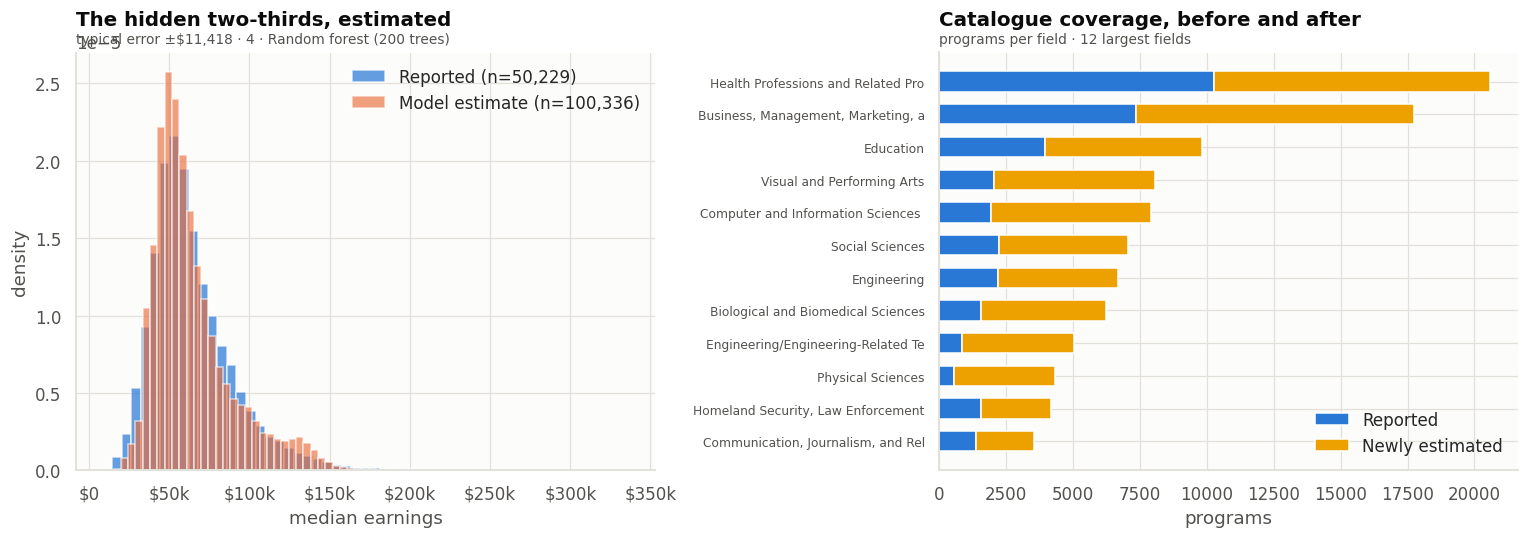

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(ana[TARGET].dropna(), bins=55, color=CAT[0], alpha=0.72, density=True,
             label=f"Reported (n={ana[TARGET].notna().sum():,})")
axes[0].hist(hid["predicted_earnings"], bins=55, color=CAT[1], alpha=0.62, density=True,
             label=f"Model estimate (n={len(hid):,})")
axes[0].xaxis.set_major_formatter(USD); axes[0].legend(loc="upper right")
finish(axes[0], "The hidden two-thirds, estimated",
       f"typical error ±${rmse_best:,.0f} · {best}", "median earnings", "density")

cov = pd.DataFrame({
    "Reported":  ana.groupby("cip_family_title", observed=True).size(),
    "Estimated": hid.groupby("cip_family_title", observed=True).size(),
}).fillna(0)
cov = cov.loc[cov.sum(axis=1).sort_values(ascending=False).head(12).index][::-1]
yy = np.arange(len(cov))
axes[1].barh(yy, cov["Reported"], height=0.62, color=CAT[0], label="Reported")
axes[1].barh(yy, cov["Estimated"], left=cov["Reported"], height=0.62, color=CAT[3],
             label="Newly estimated")
axes[1].set_yticks(yy); axes[1].set_yticklabels([t[:34] for t in cov.index], fontsize=8)
axes[1].legend(loc="lower right")
finish(axes[1], "Catalogue coverage, before and after",
       "programs per field · 12 largest fields", "programs", "")
plt.tight_layout(); plt.show()

**Read these charts.** The estimated distribution sits slightly left of the reported one and is
tighter — exactly what we should expect, since suppressed programs are smaller and the forest
pulls extremes toward the middle.

**So what — and the limitation stated plainly.** The model is trained on larger programs and
extrapolated to smaller ones, so it is **least reliable exactly where it is most novel**. Two
consequences we hold ourselves to:

1. **We publish ROI tiers, not dollar figures.** With a ±$12k error band, a precise number would
   be false precision.
2. One piece of counter-evidence worth volunteering: the two groups' *inputs* are very similar —
   destination-occupation wage and growth are close — the main difference is program size. The
   students feed similar industries; the classes are just smaller.

In [ ]:
cmp_frames = pd.DataFrame({
    "reported":   ana[["awards_year2","occupation_median_wage_2024_usd",
                       "occupation_growth_pct_2024_34","ai_exposure_index","credential_level"]].median(),
    "suppressed": hid[["awards_year2","occupation_median_wage_2024_usd",
                       "occupation_growth_pct_2024_34","ai_exposure_index","credential_level"]].median(),
})
cmp_frames["difference"] = cmp_frames["suppressed"] - cmp_frames["reported"]
print("Are the hidden programs really different? (medians)")
print(cmp_frames.round(3).to_string())
print("\nThe gap is program size, not industry destination — which supports the extrapolation.")

Are the hidden programs really different? (medians)
                                  reported  suppressed  difference
awards_year2                        35.000       6.000     -29.000
occupation_median_wage_2024_usd  82269.000   80242.000   -2027.000
occupation_growth_pct_2024_34        4.730       3.820      -0.910
ai_exposure_index                    0.031       0.038       0.006
credential_level                     3.000       3.000       0.000

The gap is program size, not industry destination — which supports the extrapolation.


## 11.2 The decision table — the actual deliverable

Academic leadership does not review programs one institution at a time. The deliverable is a table at the
level the decision is made: **field of study x credential level**, now covering 100% of the
catalogue instead of a third.

In [ ]:
full = pd.concat([
    ana.assign(earnings_used=ana[TARGET], source="reported"),
    hid.assign(earnings_used=hid["predicted_earnings"], source="estimated"),
])

decision = (full.groupby(["cip_family_title","degree_level_6"], observed=True)
    .agg(programs=("program_id","size"), grads=("awards_year2","sum"),
         n_reported=("median_earnings_4yr_usd","count"),
         earnings=("earnings_used","median"),
         debt_ratio=("debt_to_earnings_4yr","median"),
         beats_hs=("pct_above_hs_threshold_5yr","median"),
         growth=("earnings_growth_pct_1yr_to_5yr","median"),
         ai=("ai_exposure_index","median"),
         job_growth=("occupation_growth_pct_2024_34","median"))
    .dropna(subset=["earnings"]))
decision["vs_national"] = decision["earnings"] - ana[TARGET].median()

print(f"Decision table: {len(decision)} field × credential cells, "
      f"covering {decision['grads'].sum():,.0f} credentials")
print(f"  cells with ≥30 reported programs : {(decision['n_reported']>=30).sum()}")
print(f"  cells with ZERO reported programs: {(decision['n_reported']==0).sum()}  ← invisible until now")
print()
print("TOP 8 by earnings")
print(decision.nlargest(8, "earnings")[["grads","earnings","debt_ratio","beats_hs","growth","ai"]]
        .round(1).to_string())
print("\nBOTTOM 8 by earnings")
print(decision.nsmallest(8, "earnings")[["grads","earnings","debt_ratio","beats_hs","growth","ai"]]
        .round(1).to_string())

Decision table: 206 field × credential cells, covering 5,223,726 credentials
  cells with ≥30 reported programs : 105
  cells with ZERO reported programs: 31  ← invisible until now

TOP 8 by earnings
                                                                                      grads  earnings  debt_ratio  beats_hs  growth   ai
cip_family_title                                                degree_level_6                                                          
Engineering/Engineering-Related Technologies/Technicians        First Professional     51.0  146245.7         NaN       NaN     NaN  0.2
Computer and Information Sciences and Support Services          Doctoral             2824.0  142126.1         0.5      91.3     1.5  0.7
                                                                First Professional     51.0  137942.5         NaN       NaN     NaN  0.7
Engineering                                                     First Professional      8.0  136356.9         NaN  

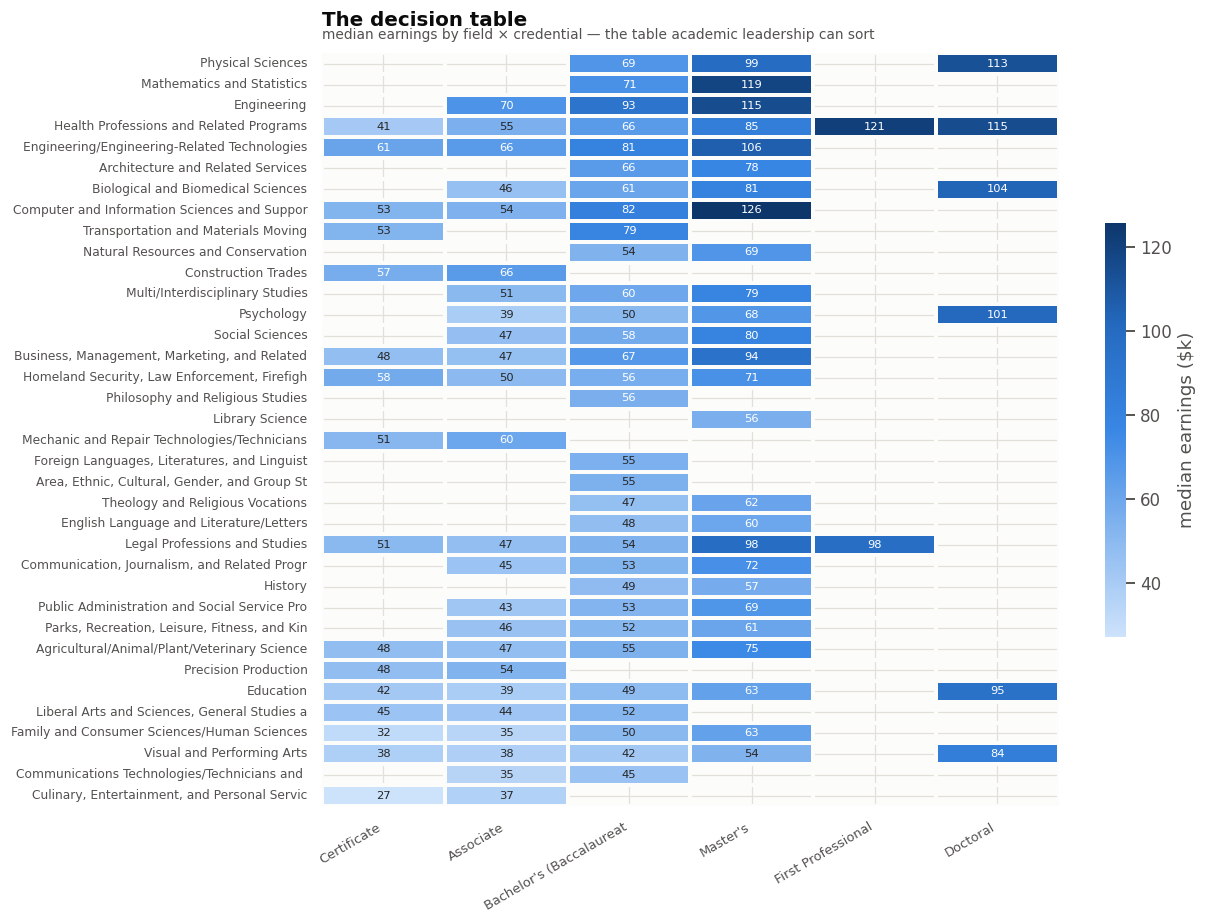

In [ ]:
solid = decision[decision["n_reported"] >= 30].copy()
heat = (solid.reset_index()
             .pivot_table(index="cip_family_title", columns="degree_level_6",
                          values="earnings", aggfunc="median"))
heat = heat.reindex(columns=[c for c in cred_order if c in heat.columns])
heat = heat.loc[heat.median(axis=1).sort_values(ascending=False).index]

fig, ax = plt.subplots(figsize=(11.5, 8.5))
sns.heatmap(heat/1000, cmap=SEQ, annot=True, fmt=".0f", annot_kws={"size": 7.5},
            linewidths=1.6, linecolor=SURFACE,
            cbar_kws={"shrink": 0.55, "label": "median earnings ($k)"}, ax=ax)
ax.set_yticklabels([t.get_text()[:44] for t in ax.get_yticklabels()], fontsize=8, rotation=0)
ax.set_xticklabels([t.get_text()[:24] for t in ax.get_xticklabels()],
                   fontsize=8.5, rotation=30, ha="right")
finish(ax, "The decision table",
       "median earnings by field × credential — the table academic leadership can sort", "", "")
plt.tight_layout(); plt.show()

---
# 12 · Business insights

Four findings. Each names the evidence behind it, because a recommendation without a citation is
an opinion.

In [ ]:
nat = ana[TARGET].median()
fail_floor = solid[solid["beats_hs"] < 60].sort_values("grads", ascending=False)
n_tier_rows = ana["roi_tier"].notna().sum()
at_risk = (ana["roi_tier"] == "At risk (>1.00)").sum()

print("=" * 74)
print("FINDING 1 · Credential level is the biggest lever — but its value depends on the field")
print("=" * 74)
print(f"  forest importance on credential_level : {pd.Series(rf.feature_importances_, index=X_train.columns)['credential_level']*100:.1f}%")
for g in ["STEM","Humanities & social sciences","Business / health / trades"]:
    print(f"  value of one level, {g:30s}: ${grp.loc[g,'value of 1 credential level']:>8,.0f}")

print("\n" + "=" * 74)
print("FINDING 2 · Changing field matters far more than changing institution")
print("=" * 74)
print(f"  Program + Occupation blocks : {by_block.get('Program',0)+by_block.get('Occupation',0):.1f}% of model importance")
print(f"  Institution block           : {by_block.get('Institution',0):.1f}%")
print(f"  field spread, top to bottom : ${fam['earn'].max()-fam['earn'].min():,.0f}")

print("\n" + "=" * 74)
print("FINDING 3 · AI exposure is a growth signal, not a risk signal")
print("=" * 74)
big = band_tbl[band_tbl["band"].astype(str).isin(["$70–85k","$85–110k",">$110k"])]
print(f"  above $70k: low-AI growth {big['growth_low_AI'].median():.0f}% "
      f"vs high-AI {big['growth_high_AI'].median():.0f}%")
if dec is not None:
    print(f"  declining trajectory: {lo_d:.1f}% low-exposure vs {hi_d:.1f}% high-exposure ({lo_d/hi_d:.1f}x)")
print(f"  high-pay/high-exposure fields cover {hi_hi['grads'].sum()/q['grads'].sum()*100:.1f}% of credentials")

print("\n" + "=" * 74)
print("FINDING 4 · Two-thirds of the catalogue is visible for the first time")
print("=" * 74)
print(f"  programs scored : {len(hid):,}")
print(f"  coverage        : {len(ana)/len(d)*100:.1f}% → 100%")
print(f"  cells that had NO reported program at all: {(decision['n_reported']==0).sum()}")

print("\n" + "=" * 74)
print("THE HARD CASES — programs failing the floor test")
print("=" * 74)
print(f"  cells where <60% of graduates out-earn a high-school graduate: {len(fail_floor)}")
print(f"  covering {fail_floor['grads'].sum():,.0f} credentials a year")
print(fail_floor[["grads","earnings","beats_hs","debt_ratio","ai"]].head(6).round(1).to_string())

print("\n" + "=" * 74)
print("DEBT — and the denominator that matters")
print("=" * 74)
print(f"  at-risk programs (debt > 1x earnings): {at_risk:,}")
print(f"    = {at_risk/n_tier_rows*100:.1f}% of the {n_tier_rows:,} programs WITH debt+earnings data")
print(f"    = {at_risk/len(d)*100:.2f}% of the full {len(d):,}-row analysis frame")
print("  ALWAYS quote the denominator when using this number.")

FINDING 1 · Credential level is the biggest lever — but its value depends on the field
  forest importance on credential_level : 19.4%
  value of one level, STEM                          : $  12,341
  value of one level, Humanities & social sciences  : $   8,146
  value of one level, Business / health / trades    : $   9,185

FINDING 2 · Changing field matters far more than changing institution
  Program + Occupation blocks : 66.8% of model importance
  Institution block           : 21.6%
  field spread, top to bottom : $68,409

FINDING 3 · AI exposure is a growth signal, not a risk signal
  above $70k: low-AI growth 10% vs high-AI 29%
  declining trajectory: 9.3% low-exposure vs 2.9% high-exposure (3.2x)
  high-pay/high-exposure fields cover 40.2% of credentials

FINDING 4 · Two-thirds of the catalogue is visible for the first time
  programs scored : 100,336
  coverage        : 33.4% → 100%
  cells that had NO reported program at all: 31

THE HARD CASES — programs failing the floor t

---
# 13 · Recommendations for academic leadership

| Action | Target | Rationale |
|---|---|---|
| **EXPAND** | High-AI-exposure, high-pay fields — Computer Science, Engineering, Mathematics, Business — plus stackable credential pathways | Above $70k in early-career pay, high-exposure groups show 29% median growth versus 10% for low-exposure groups; this is a screening association, while the credential ladder remains the strongest lever |
| **HOLD** | Programs in the middle ROI tier; meanwhile put AI tooling into their curriculum | Protects the bulk of the catalogue at low cost |
| **RESTRUCTURE** | Programs failing the floor test — especially low AI exposure combined with a low share of graduates out-earning a high-school graduate | A short, reviewable list rather than a blanket cut |

> **None of these are causal claims.** Students select into fields on ability and preference, so
> every recommendation is a **screening and prioritisation** decision — where to look first — not
> a promise about what a degree causes.

## 13.1 The four questions the brief names

**Who can benefit from the data?** The academic leadership and budget committee (primary audience);
the financial-aid office, to flag high-debt programs before students borrow; deans and
curriculum committees, deciding where AI tooling belongs in the syllabus; and prospective
students and advisors wanting realistic expectations by field and level.

**How would the data help them make better decisions?** It replaces enrolment demand and
departmental advocacy with an outcome measure; turns a 33%-visible catalogue into a
100%-comparable one; and converts "which programs are risky" from an opinion into a ranked,
evidence-backed shortlist.

**What other data would be useful to have?** Student-level records are the single biggest gap —
without them we cannot separate the effect of the program from the students who chose it.
Then: multi-year earnings cohorts (one snapshot cannot distinguish structural decline from a
cyclical dip); completion and time-to-degree rates (strong earnings with a 40% completion rate
is not a good program); regional wage data (national medians understate the local variation a
regional university actually competes in); and an AI measure that separates augmentation from
displacement.

**What are your key insights and recommendations?** Section 12 and the table above.

---
# 14 · Limitations

- **Association, not causation.** Students self-select into majors on ability and preparation,
  none of which we observe.
- **The target is missing-not-at-random.** The model trains on larger programs and extrapolates
  to smaller ones, so it is least trustworthy exactly where it is most novel. §11 quantifies how
  similar the two groups' inputs are, which mitigates but does not remove this.
- **A single snapshot.** With no multi-year cohorts, structural decline and a cyclical dip look
  identical. The 1→5 year growth we use in §9 is within-cohort, not across cohorts.
- **AI exposure is a proxy.** O\*NET records tool *presence*; it does not measure displacement
  risk. Section 9 is deliberately framed around what the measure can support.
- **Median of medians.** Field-level figures are medians of program medians, which understates
  within-field spread.
- **The ROI-tier denominator.** Debt-to-earnings exists for only ~19% of the analysis frame.
  Every percentage quoted from it must name that denominator.

# 15 · Future work

1. Validate the hidden-program estimates against a state unemployment-insurance wage panel.
2. Add gradient boosting and quantile regression to produce genuine prediction intervals.
3. Model completion rate jointly with earnings for a true expected-value-per-enrolled-student.
4. Rebuild the AI index on task-level exposure rather than tool counts.
5. Re-estimate with sample weights correcting for the size-driven suppression mechanism.

# 16 · Reflection on AI tools

**What AI helped with.** Debugging, chart scaffolding, quickly making sense of unfamiliar
columns in a 72-column file, and drafting prose.

**How we validated it.** Every figure in this notebook was re-run end to end from a clean
runtime. Model metrics are reported on a held-out set we never tuned against, and we added a
**no-model benchmark** specifically so that "the model works" could be falsified rather than
assumed. Every AI-suggested interpretation was traced back to the underlying chart before it
was written down.

**What that caught.** Two real bugs, both documented in §7:

1. The AI exposure index was min-max scaled *separately* on the reported and hidden frames, so
   the same value meant different things on each side of the very split the model has to cross.
2. An "earnings premium" metric compared 4-year-out earnings against a whole-career median wage
   and reported −27%, which reads as "every program underperforms the market." It was comparing
   early career against mid career.

Neither would have produced an error message. Both were caught by checking a number that looked
wrong against what it was supposed to mean — which is the habit, not the tool.